# INN Hotels Project

## Context

A significant number of hotel bookings are called-off due to cancellations or no-shows. The typical reasons for cancellations include change of plans, scheduling conflicts, etc. This is often made easier by the option to do so free of charge or preferably at a low cost which is beneficial to hotel guests but it is a less desirable and possibly revenue-diminishing factor for hotels to deal with. Such losses are particularly high on last-minute cancellations.

The new technologies involving online booking channels have dramatically changed customers’ booking possibilities and behavior. This adds a further dimension to the challenge of how hotels handle cancellations, which are no longer limited to traditional booking and guest characteristics.

The cancellation of bookings impact a hotel on various fronts:
* Loss of resources (revenue) when the hotel cannot resell the room.
* Additional costs of distribution channels by increasing commissions or paying for publicity to help sell these rooms.
* Lowering prices last minute, so the hotel can resell a room, resulting in reducing the profit margin.
* Human resources to make arrangements for the guests.

## Objective
The increasing number of cancellations calls for a Machine Learning based solution that can help in predicting which booking is likely to be canceled. INN Hotels Group has a chain of hotels in Portugal, they are facing problems with the high number of booking cancellations and have reached out to your firm for data-driven solutions. You as a data scientist have to analyze the data provided to find which factors have a high influence on booking cancellations, build a predictive model that can predict which booking is going to be canceled in advance, and help in formulating profitable policies for cancellations and refunds.

## Data Description
The data contains the different attributes of customers' booking details. The detailed data dictionary is given below.


**Data Dictionary**

* Booking_ID: unique identifier of each booking
* no_of_adults: Number of adults
* no_of_children: Number of Children
* no_of_weekend_nights: Number of weekend nights (Saturday or Sunday) the guest stayed or booked to stay at the hotel
* no_of_week_nights: Number of week nights (Monday to Friday) the guest stayed or booked to stay at the hotel
* type_of_meal_plan: Type of meal plan booked by the customer:
    * Not Selected – No meal plan selected
    * Meal Plan 1 – Breakfast
    * Meal Plan 2 – Half board (breakfast and one other meal)
    * Meal Plan 3 – Full board (breakfast, lunch, and dinner)
* required_car_parking_space: Does the customer require a car parking space? (0 - No, 1- Yes)
* room_type_reserved: Type of room reserved by the customer. The values are ciphered (encoded) by INN Hotels.
* lead_time: Number of days between the date of booking and the arrival date
* arrival_year: Year of arrival date
* arrival_month: Month of arrival date
* arrival_date: Date of the month
* market_segment_type: Market segment designation.
* repeated_guest: Is the customer a repeated guest? (0 - No, 1- Yes)
* no_of_previous_cancellations: Number of previous bookings that were canceled by the customer prior to the current booking
* no_of_previous_bookings_not_canceled: Number of previous bookings not canceled by the customer prior to the current booking
* avg_price_per_room: Average price per day of the reservation; prices of the rooms are dynamic. (in euros)
* no_of_special_requests: Total number of special requests made by the customer (e.g. high floor, view from the room, etc)
* booking_status: Flag indicating if the booking was canceled or not.

## Importing necessary libraries and data

In [1]:
#Filter the warnings
import warnings

warnings.filterwarnings("ignore")
from statsmodels.tools.sm_exceptions import ConvergenceWarning

warnings.simplefilter("ignore", ConvergenceWarning)

# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)
# setting the precision of floating numbers to 5 decimal points
pd.set_option("display.float_format", lambda x: "%.5f" % x)

# Library to split data
from sklearn.model_selection import train_test_split

# To build model for prediction
import statsmodels.stats.api as sms
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from statsmodels.tools.tools import add_constant
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# To tune different models
from sklearn.model_selection import GridSearchCV


# To get diferent metric scores
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
    make_scorer,
)

In [2]:
hotel = pd.read_csv("data/INNHotelsGroup.csv")

Mounted at /content/drive


In [3]:
data = hotel.copy()

## Data Overview




### Observations and Sanity Checks

####Read the first and last 5 rows of the data set

In [4]:
#read first 5 rows of the data set
data.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00000,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68000,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00000,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00000,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50000,0,Canceled


In [5]:
#read last 5 rows of the data set
data.tail()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
36270,INN36271,3,0,2,6,Meal Plan 1,0,Room_Type 4,85,2018,8,3,Online,0,0,0,167.80000,1,Not_Canceled
36271,INN36272,2,0,1,3,Meal Plan 1,0,Room_Type 1,228,2018,10,17,Online,0,0,0,90.95000,2,Canceled
36272,INN36273,2,0,2,6,Meal Plan 1,0,Room_Type 1,148,2018,7,1,Online,0,0,0,98.39000,2,Not_Canceled
36273,INN36274,2,0,0,3,Not Selected,0,Room_Type 1,63,2018,4,21,Online,0,0,0,94.50000,0,Canceled
36274,INN36275,2,0,1,2,Meal Plan 1,0,Room_Type 1,207,2018,12,30,Offline,0,0,0,161.67000,0,Not_Canceled


#### Look at the shape of the data set

In [6]:
data.shape

(36275, 19)

There are 36725 Rows with 19 columns in the data set

#### Look at the data types of the data set

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  object 
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date   

- The dependent variable is booking status which is categorized as an 'object' meaning it is categorical in nature

The independent vaiables in the data set are composed of 3 data types:

- 1 variable with 'float' data type -- avg_price_per_room
- 13 variables with 'integer' data type -- no_of_adults, no_of_children, no_of weekend_nights, no_of_week_nights, required_car_parking_space, lead_time, arrival_year, arrival_month, arrival_date, repeated_guest, no_of_previous_cancellations, no_of_previous_bookings_not_cancelled, no_of_special_requests
- 4 variables with 'object' data type (excluding the dependent variable booking_status which is the 5th 'object' variable in the dataset ) -- Booking_ID, type_of_meal_plan, room_type_reserved, market_segment_type
- There don't seem to be any missing values in the dataset

#### Check for duplicates

In [8]:
#check for duplicates
data.duplicated().sum()

0

There are no duplicates

In [9]:
#check for missing values
data.isnull().sum()

Booking_ID                              0
no_of_adults                            0
no_of_children                          0
no_of_weekend_nights                    0
no_of_week_nights                       0
type_of_meal_plan                       0
required_car_parking_space              0
room_type_reserved                      0
lead_time                               0
arrival_year                            0
arrival_month                           0
arrival_date                            0
market_segment_type                     0
repeated_guest                          0
no_of_previous_cancellations            0
no_of_previous_bookings_not_canceled    0
avg_price_per_room                      0
no_of_special_requests                  0
booking_status                          0
dtype: int64

There is no missing values in the dataset

#### Drop the Booking_ID Column since it will no longer be necessary

In [10]:
#double checking to be sure that all the values in the Booking_ID are unique
data.Booking_ID.nunique()

36275

In [11]:
#Dropping the booking ID in the dataset and checking to see that the column was dropped succesffully
data = data.drop('Booking_ID', axis= 1)
data.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00000,0,Not_Canceled
1,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68000,1,Not_Canceled
2,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00000,0,Canceled
3,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00000,0,Canceled
4,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50000,0,Canceled


## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Leading Questions**:
1. What are the busiest months in the hotel?
2. Which market segment do most of the guests come from?
3. Hotel rates are dynamic and change according to demand and customer demographics. What are the differences in room prices in different market segments?
4. What percentage of bookings are canceled?
5. Repeating guests are the guests who stay in the hotel often and are important to brand equity. What percentage of repeating guests cancel?
6. Many guests have special requirements when booking a hotel room. Do these requirements affect booking cancellation?

In [12]:
#Check the statistical summary of the data
data.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_adults,36275.00000,1.84496,0.51871,0.00000,2.00000,2.00000,2.00000,4.00000
no_of_children,36275.00000,0.10528,0.40265,0.00000,0.00000,0.00000,0.00000,10.00000
no_of_weekend_nights,36275.00000,0.81072,0.87064,0.00000,0.00000,1.00000,2.00000,7.00000
no_of_week_nights,36275.00000,2.20430,1.41090,0.00000,1.00000,2.00000,3.00000,17.00000
required_car_parking_space,36275.00000,0.03099,0.17328,0.00000,0.00000,0.00000,0.00000,1.00000
lead_time,36275.00000,85.23256,85.93082,0.00000,17.00000,57.00000,126.00000,443.00000
arrival_year,36275.00000,2017.82043,0.38384,2017.00000,2018.00000,2018.00000,2018.00000,2018.00000
arrival_month,36275.00000,7.42365,3.06989,1.00000,5.00000,8.00000,10.00000,12.00000
arrival_date,36275.00000,15.59700,8.74045,1.00000,8.00000,16.00000,23.00000,31.00000
repeated_guest,36275.00000,0.02564,0.15805,0.00000,0.00000,0.00000,0.00000,1.00000


- Average price per room and number of adults both have 0 as there minimums which seem to be a bit odd, the two should be looked at closer to see how prevalent and why these have 0 values

- The mean average price per room is 99.45 Euros, with the max avg price per room being 540 Euros.

- The average lead time to the booking is 57 days with the max being over a year in advance at 443 days. The minimum lead time to the booking is 0 days which represents a same day booking.

In [13]:
#Check to see how many bookings have zero adults
len(data[data['no_of_adults']==0])

139

- There are 139 bookings with 0 adults which only makes up a small sample of the data set, it is possible that these bookings were made by adults for children as a separate room and they show up under a different Booking ID.
- We will keep this data as is, but will check with INN hotels to see if this assumption is correct.

In [14]:
#Summary of categorical variables
data.describe(include='object').T

,count,unique,top,freq
type_of_meal_plan,36275,4,Meal Plan 1,27835
room_type_reserved,36275,7,Room_Type 1,28130
market_segment_type,36275,5,Online,23214
booking_status,36275,2,Not_Canceled,24390


- There are 5 types of market segment, however online is the most common with 23214 bookings falling into this category
- Most bookings are not cancelled however nearly 12000 bookings which represents ~30% of all bookings
- Room Type 1 is the most common booking

In [15]:
#Check to see the categorical variables under market segment type
data['market_segment_type'].unique()

array(['Offline', 'Online', 'Corporate', 'Aviation', 'Complementary'],
      dtype=object)

We can see there is a market segment category labeled complimentary, which now explains the 0 Euro values seen in avg price per room. We will explore this further in the EDA to verify this assumption.

In [16]:
#Check to see the categorical variables under room type reserved
data['room_type_reserved'].unique()

array(['Room_Type 1', 'Room_Type 4', 'Room_Type 2', 'Room_Type 6',
       'Room_Type 5', 'Room_Type 7', 'Room_Type 3'], dtype=object)

In [17]:
#Check to see the categorical variables under type of meal plan
data['type_of_meal_plan'].unique()

array(['Meal Plan 1', 'Not Selected', 'Meal Plan 2', 'Meal Plan 3'],
      dtype=object)

###Define Functions for EDA

In [18]:
#function to create a subplot with boxplot and histogram using a shared x - axis
def histogram_boxplot (data, feature, figsize=(15,10), kde=False, bins=None):
  """
  Combined Histogram and Boxplot for Visualization

  data: dataframe
  feature: dataframe column
  figsize: size of the figure (default is 15:10)
  kde: whether to show the density curve (default False)
  bins: numbers of bins for histogram (default False)
  """
  f2, (ax_box2, ax_hist2) = plt.subplots(
      nrows=2, #number of rows for the subplot grid set to 2
      sharex=True, #x-axis shared between the subplots
      gridspec_kw={'height_ratios': (.25,.75)},
      figsize=figsize,
  ) #creating the 2 subplots
  sns.boxplot(
      data=data, x=feature, ax=ax_box2, showmeans= True, color='violet'
  ) #boxplot created with a traingle to indicate the mean value
  sns.histplot(
      data=data, x=feature, kde=kde, ax=ax_hist2, bins = bins
  ) if bins else sns.histplot(
      data=data, x=feature, kde=kde, ax=ax_hist2
  ) #for histogram
  ax_hist2.axvline(
      data[feature].mean(), color='green', linestyle= '--'
  ) #add mean to the histogram
  ax_hist2.axvline(
      data[feature].median(), color = 'black', linestyle = "-"
  ) #add median to the histogram


In [19]:
#function to create labeled barplots
def labeled_barplot(data, feature, perc=False, n=None):
  """
  barplot with counts or percentage at the top

  data: dataframe
  feature: dataframe column
  perc: whether to show percentages or counts (default is False)
  n: displays the top n category levels (default is None, i.e., display all levels)
  """

  total= len(data[feature]) #length of the column
  count= data[feature].nunique()
  if n is None:
    plt.figure(figsize=(count+2, 6))
  else:
    plt.gifure(figsize=(n+2 , 6))

  plt.title(feature)
  plt.xticks(rotation=90, fontsize=15)
  ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
  )

  for p in ax.patches:
      if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
      else:
            label = p.get_height()  # count of each level of the category

      x = p.get_x() + p.get_width() / 2  # width of the plot
      y = p.get_height()  # height of the plot

      ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

  plt.show()  # show the plot



In [20]:
#function to create a stacked barplot
def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 5, 5))
    plt.legend(
        loc="lower left", frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

In [21]:
### function to plot distributions with respect to target


def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
        stat="density",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
        stat="density",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], showmeans=True, palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showmeans=True,
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

### Univariate Analysis

#### Lead Time Observations

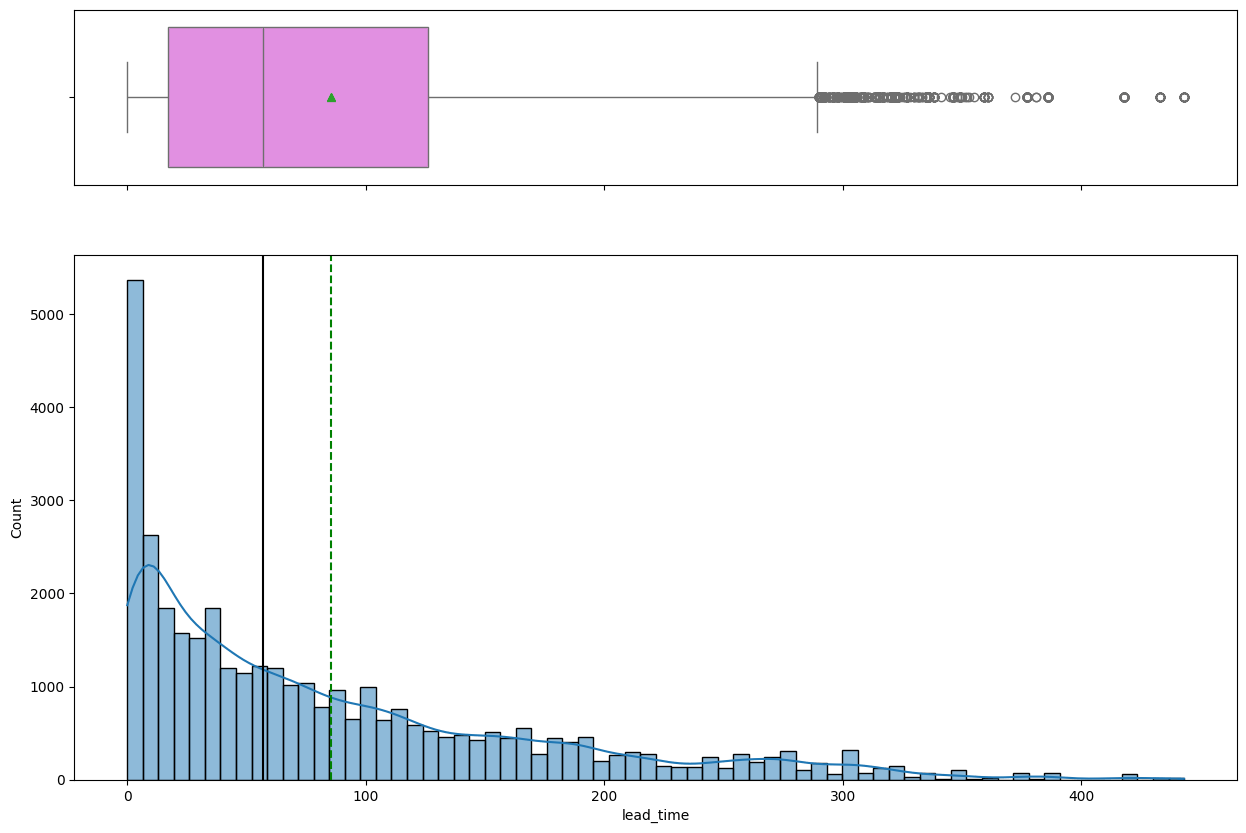

In [22]:
#visualize lead time
histogram_boxplot(data, 'lead_time', kde=True)

- The distribution is right skewed with most bookings occuring under 100 days
- There are outliers above the upper whisker, however we'll keep these as they are likely to be true values.

#### Average price per room observations

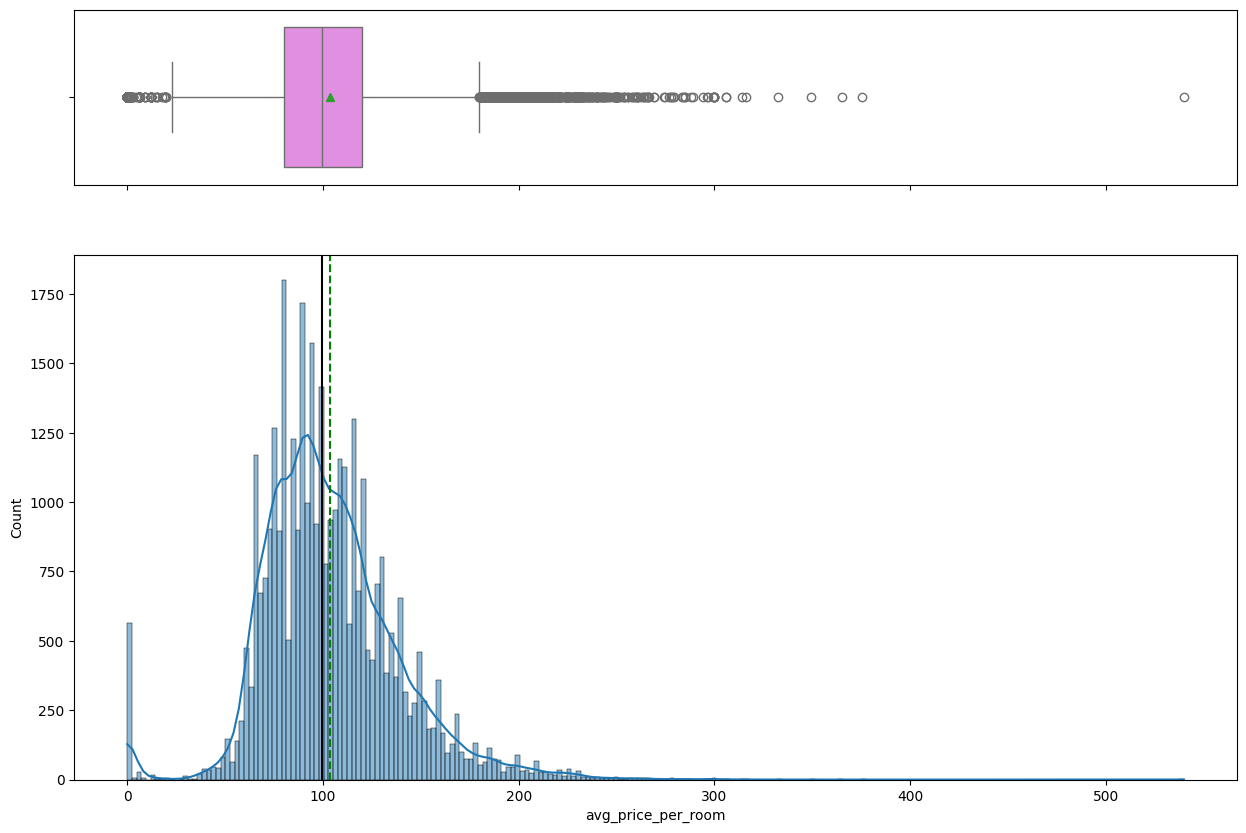

In [23]:
#visualize avg price per room
histogram_boxplot(data, 'avg_price_per_room', kde=True)

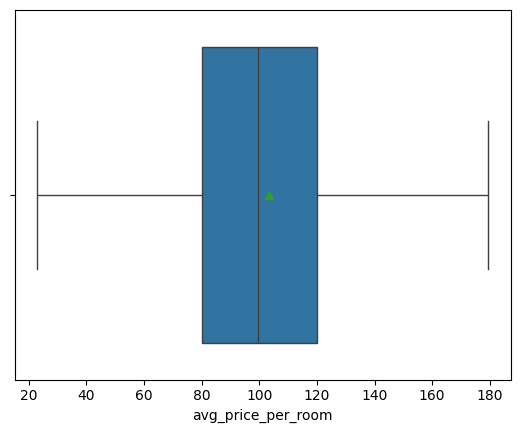

In [24]:
#visualize the distribution without outliers
sns.boxplot(data=data, x='avg_price_per_room', showfliers=False, showmeans=True)
plt.show()

- If outliers are removed the distribution of average price per room is relatively normal.
- There is a large instance of avg price per room being 0 Euros, which we can explore deeper
- There is an instance of a very large outlier above 500 euros which we will dive into as well

In [25]:
#Pulling the bookings with an average room price of zero
data[data['avg_price_per_room']== 0]

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
63,1,0,0,1,Meal Plan 1,0,Room_Type 1,2,2017,9,10,Complementary,0,0,0,0.00000,1,Not_Canceled
145,1,0,0,2,Meal Plan 1,0,Room_Type 1,13,2018,6,1,Complementary,1,3,5,0.00000,1,Not_Canceled
209,1,0,0,0,Meal Plan 1,0,Room_Type 1,4,2018,2,27,Complementary,0,0,0,0.00000,1,Not_Canceled
266,1,0,0,2,Meal Plan 1,0,Room_Type 1,1,2017,8,12,Complementary,1,0,1,0.00000,1,Not_Canceled
267,1,0,2,1,Meal Plan 1,0,Room_Type 1,4,2017,8,23,Complementary,0,0,0,0.00000,1,Not_Canceled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35983,1,0,0,1,Meal Plan 1,0,Room_Type 7,0,2018,6,7,Complementary,1,4,17,0.00000,1,Not_Canceled
36080,1,0,1,1,Meal Plan 1,0,Room_Type 7,0,2018,3,21,Complementary,1,3,15,0.00000,1,Not_Canceled
36114,1,0,0,1,Meal Plan 1,0,Room_Type 1,1,2018,3,2,Online,0,0,0,0.00000,0,Not_Canceled
36217,2,0,2,1,Meal Plan 1,0,Room_Type 2,3,2017,8,9,Online,0,0,0,0.00000,2,Not_Canceled


In [26]:
#Checking the distribution of the 0 Euro avg price based on market segment type
data.loc[data['avg_price_per_room']== 0, 'market_segment_type'].value_counts()

Complementary    354
Online           191
Name: market_segment_type, dtype: int64

- There are 545 rows with an average price of 0 Euros
- We can see 354 of the 0 values for avg price per room are under complimentary while the remaining are online. It would be wise to reference INN hotels for an explanation on if this is a true or miss classified data point.
- If it was missclassified then we would convert these to the complementary group

In [27]:
#Check bookings with avg price above 300 Euros
data[data['avg_price_per_room']> 300]

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
4150,2,2,1,2,Meal Plan 1,0,Room_Type 7,4,2018,7,8,Online,0,0,0,306.00000,3,Not_Canceled
9461,3,0,0,2,Meal Plan 1,0,Room_Type 4,21,2018,12,30,Online,0,0,0,375.50000,0,Not_Canceled
13944,2,2,0,1,Meal Plan 2,1,Room_Type 6,6,2018,8,13,Online,0,0,0,316.00000,0,Canceled
14773,2,2,0,3,Meal Plan 1,0,Room_Type 6,28,2018,6,2,Online,0,0,0,332.57000,1,Not_Canceled
20900,2,1,1,2,Meal Plan 2,0,Room_Type 1,173,2018,7,25,Offline,0,0,0,365.00000,1,Canceled
25670,2,2,1,2,Meal Plan 2,0,Room_Type 6,11,2018,9,16,Online,0,0,0,306.00000,0,Canceled
33114,2,0,0,1,Meal Plan 1,0,Room_Type 1,35,2018,3,25,Offline,0,0,0,540.00000,0,Canceled
33955,2,0,1,2,Meal Plan 2,0,Room_Type 4,57,2018,12,30,Online,0,0,0,314.10000,0,Not_Canceled
34306,2,2,0,3,Meal Plan 2,0,Room_Type 6,43,2018,12,29,Online,0,0,0,349.63000,1,Not_Canceled


- There are 9 bookings with an average room price above 300 Euros, with 1 booking having an average room price above 500 Euros. The booking was made offline which could lead to an input error due to human error. Also, when referencing other bookings with similar room type this data point can be treated.
- We'll impute the row with the value of the upper whisker since it will be representative of higher priced room falling into the distriubtion. Imputing with the mean and median would drop the price of the room into down to ~100 Euros, which would not be a good representation of the true price.


In [28]:
#Find the IQR with the values of Q1 and Q3
Q1 = data['avg_price_per_room'].quantile(.25)
Q3 = data['avg_price_per_room'].quantile(.75)

IQR= Q3-Q1

#upper whisker calculation
upper_whisker = Q3 + 1.5 * IQR
upper_whisker

179.55

- The upper whisker value is 179.55


In [29]:
#impute with the upper whisker
data.loc[data['avg_price_per_room']>500, 'avg_price_per_room']= upper_whisker

#check to see change was made correctly
data[data['avg_price_per_room']>500]

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status


- The outlier has been imputed with the upper whisker value of 179.55

#### Observations on number of previous booking cancellations

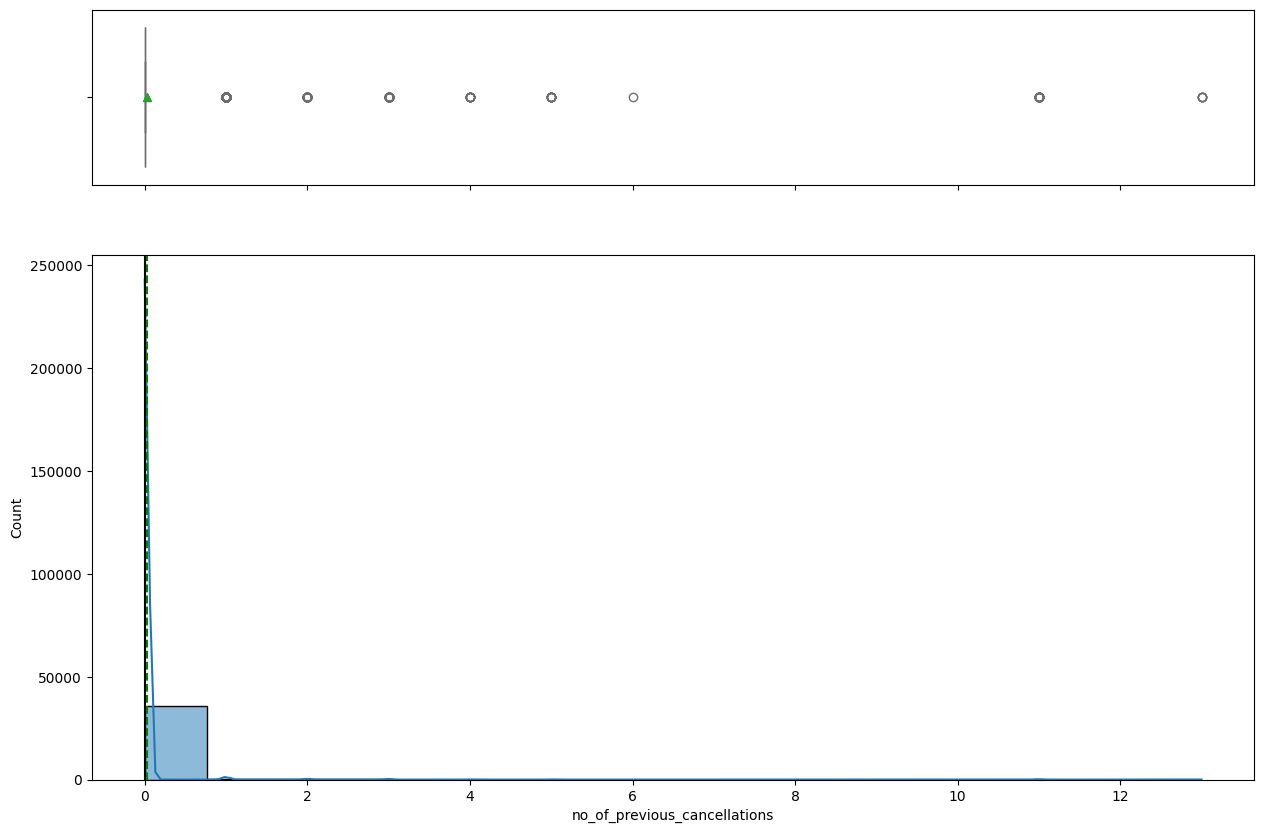

In [30]:
#visualize number of previous booking cancelled
histogram_boxplot(data, 'no_of_previous_cancellations', kde=True)

- The distribution is heavily right sweked with almost all bookings not having a previous cancellation
- There are instances of repeat cancellations

In [31]:
#See how many people cancelled on a previous booking and booked again and how many people have cancelled more than once
print('number of people who have cancelled at least once',len(data[data['no_of_previous_cancellations']>0]))
print('number of people who have cancelled more than once',len(data[data['no_of_previous_cancellations']>1]))

number of people who have cancelled at least once 338
number of people who have cancelled more than once 140


- There are 338 guests who have cancelled at least once in the past
- There are 140 repeat cancellation guests with more than 1 booking cancelled in the past
- The max previous cancellations is 13

####Observations on number of previous booking non cancellations

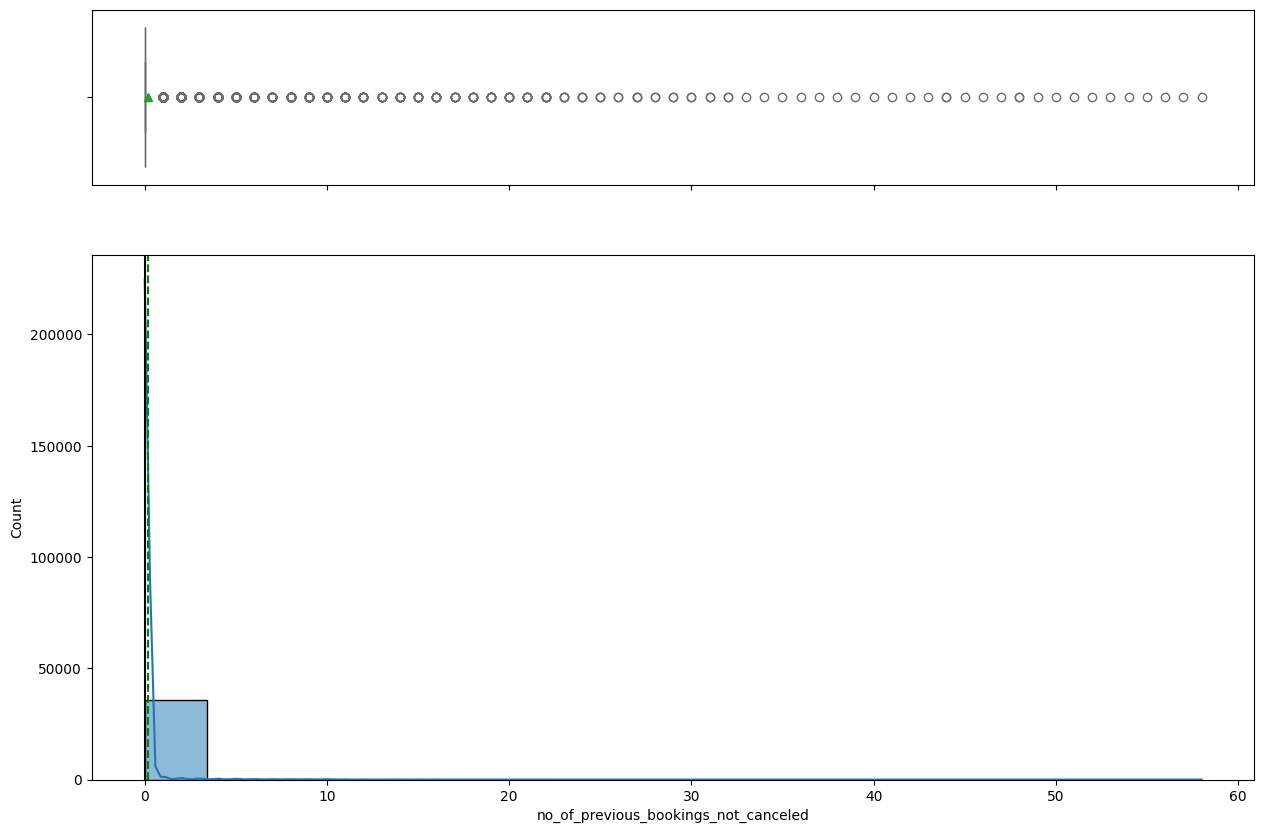

In [32]:
#visualize number of previous bookings cancelled
histogram_boxplot(data, 'no_of_previous_bookings_not_canceled', kde=True)

- We can see a similar shaped graph to bookings cancelled with a heavy right skew
- There are some repeat guests who have visited over 50 times previously regularly staying at the hotel various times within the given time frame.

####Number of adults observation

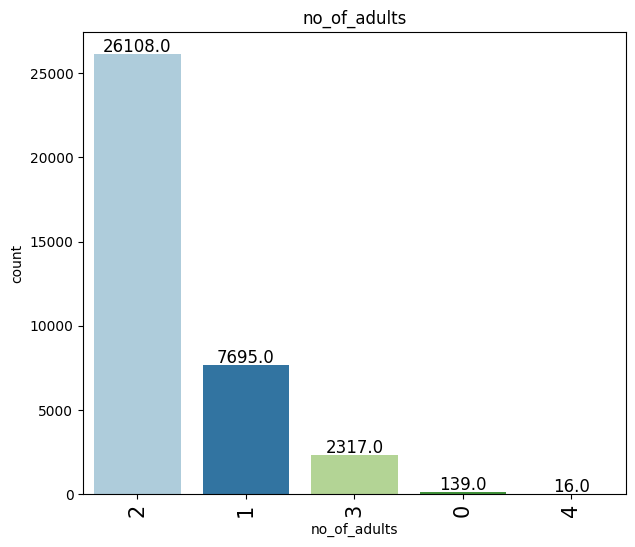

In [33]:
#visualize number of adults
labeled_barplot(data, 'no_of_adults')

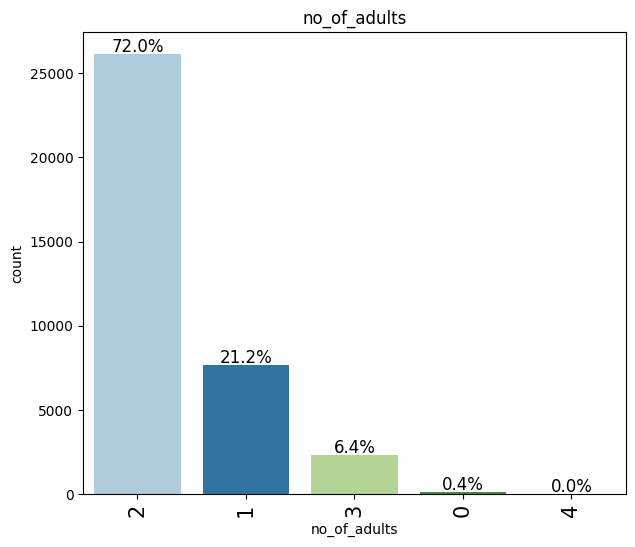

In [34]:
#visualize the percentage distribution of number of adults
labeled_barplot(data, 'no_of_adults', perc=True)

- Most bookings have two adults staying, showing that most people travel together with 26108 bookings making up 72% of the bookings
- 4 adults is rare with only 16 bookings
- 139 have no adults which was covered earlier
- 1 Adult makes up 21.2% of the bookings
- 6.4% of the bookings have 3 adults


####Observations on Number of Children


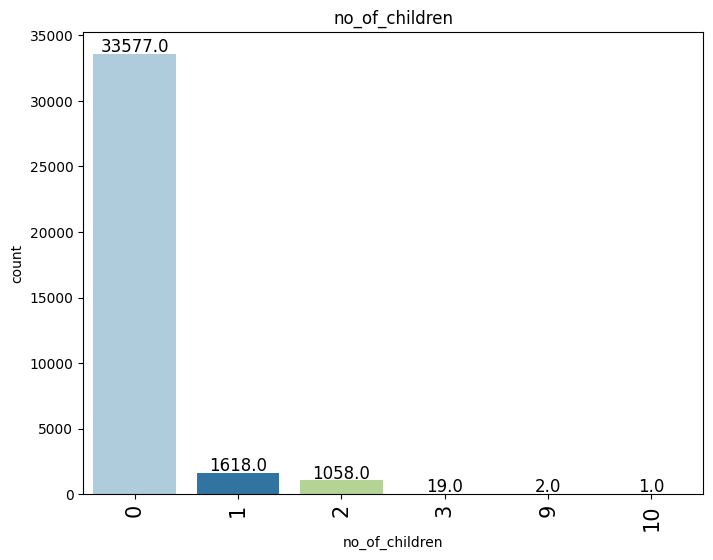

In [35]:
#visualize number of children
labeled_barplot(data, 'no_of_children')

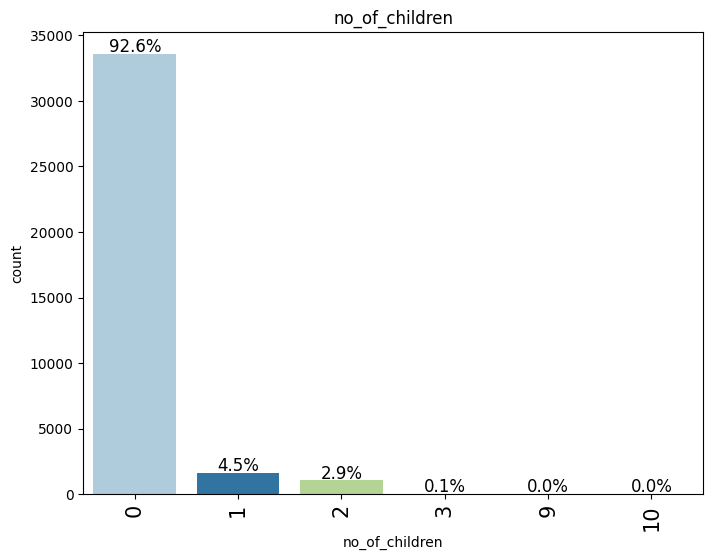

In [36]:
#visualize the percentage distribution of number of adults
labeled_barplot(data, 'no_of_children', perc=True)

- Most travel with no children 92.6%
- There are instances where 9 or 10 children have been included in the booking. This seems unlikely so we'll treat these valus since it's only 3 bookings total between the two. It is unlikely this many people would fit into a single room.

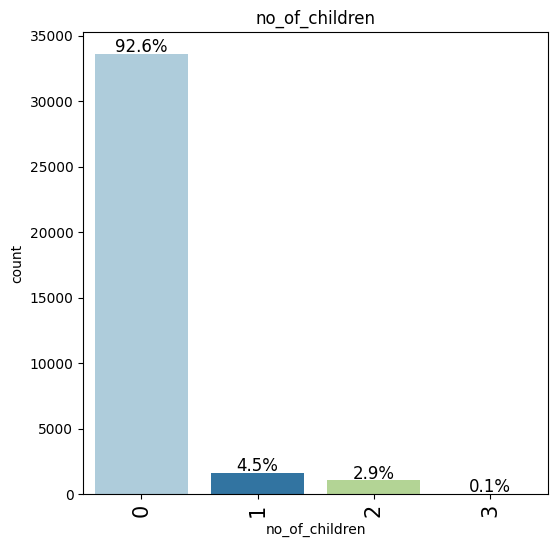

In [37]:
#imputing number of children values of 9 and 10 with the highest common occurence, 3 children (2.9%)
data['no_of_children'] = data['no_of_children'].replace([9,10], 3)

#visualize the percentage distribution of number of adults
labeled_barplot(data, 'no_of_children', perc=True)

- Number of children outliers has been treated

####Observations on number of week nights

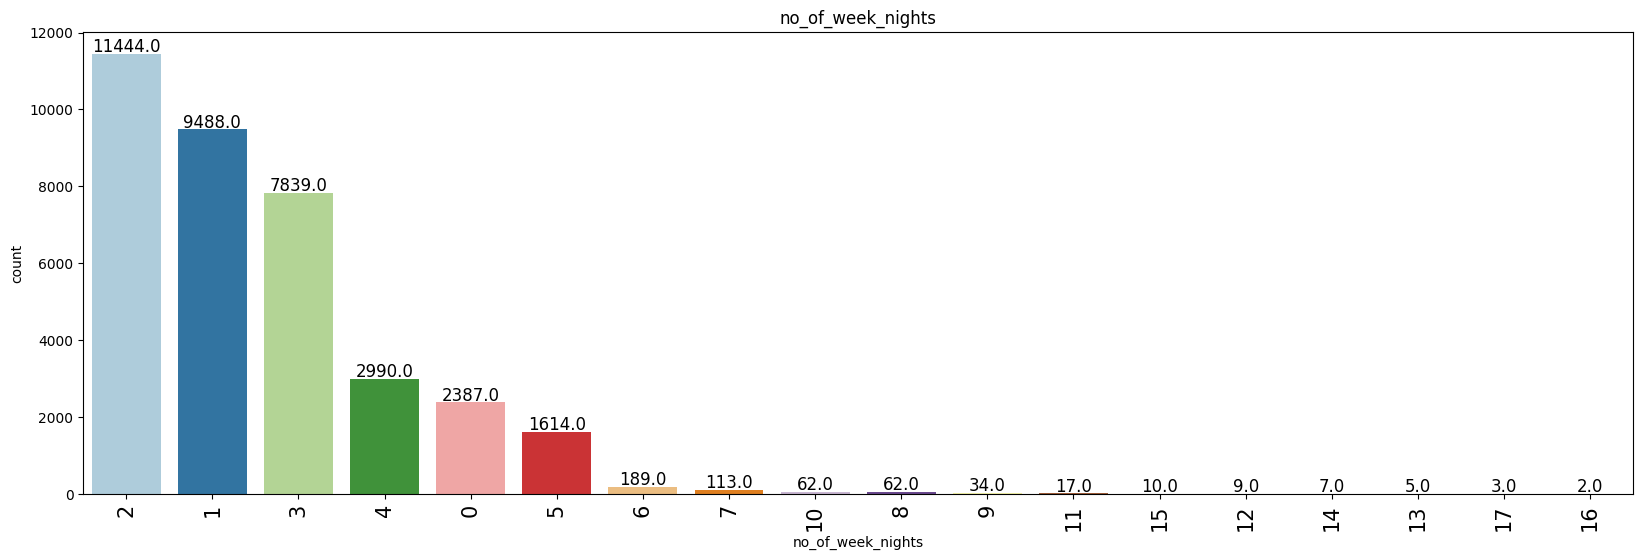

In [38]:
#visualize the number of weeknights
labeled_barplot(data, 'no_of_week_nights')

- Most all the booking are between 0-5 weeknights with 2 weeknights being the most common
- There are some extended stay which have more than 10 weeknights booked

####Observations on number of weekend nights

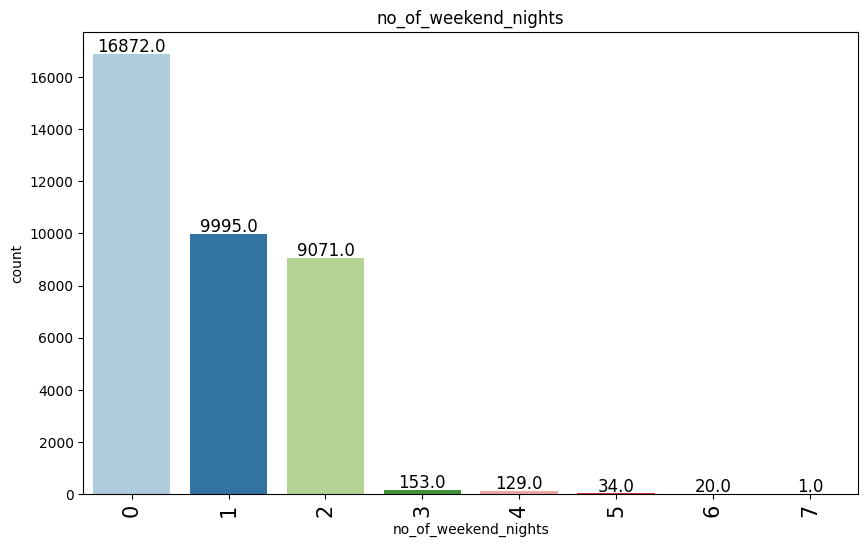

In [39]:
#Visualize number of weekend nights
labeled_barplot(data, 'no_of_weekend_nights')

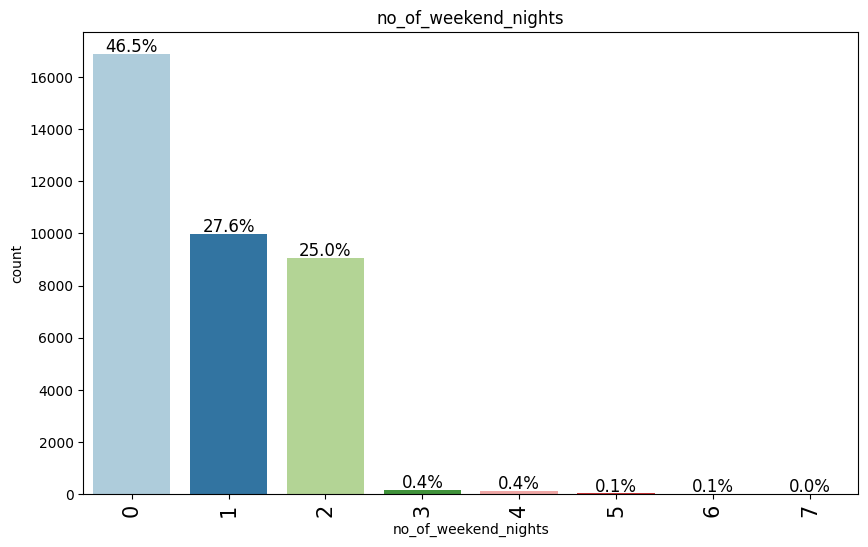

In [40]:
#Visualize percentange number of weekend nights
labeled_barplot(data, 'no_of_weekend_nights', perc = True)

- Most bookings have beetween 0-2 weekend nights booked, interestingly 0 is the most common booking with nearly half of the bookings not having a weeknight included in the booking

####Observations on number of required car parking spaces

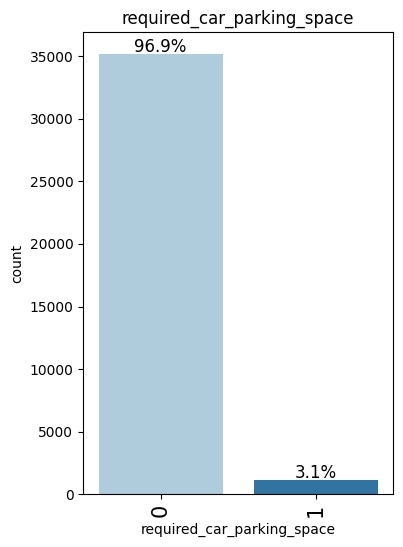

In [41]:
#visualize required car parking space
labeled_barplot(data, 'required_car_parking_space', perc= True)

- Nearly 97 percent of bookings do not require a parking space, meaning most guests are likely using alternative forms of transportation( public, taxi/ridsehare, walking)

####Observations on room type reserved

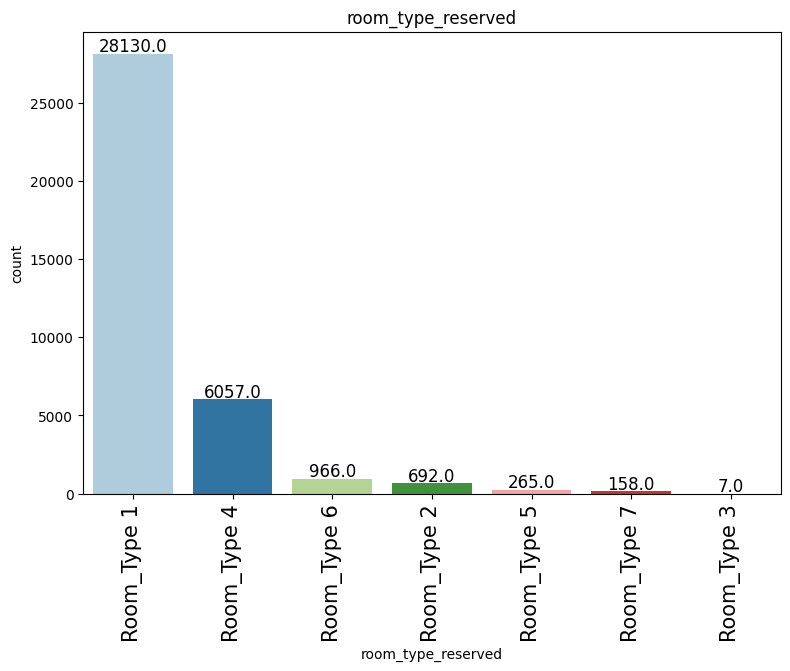

In [42]:
#visualize room type reserved
labeled_barplot(data, 'room_type_reserved')

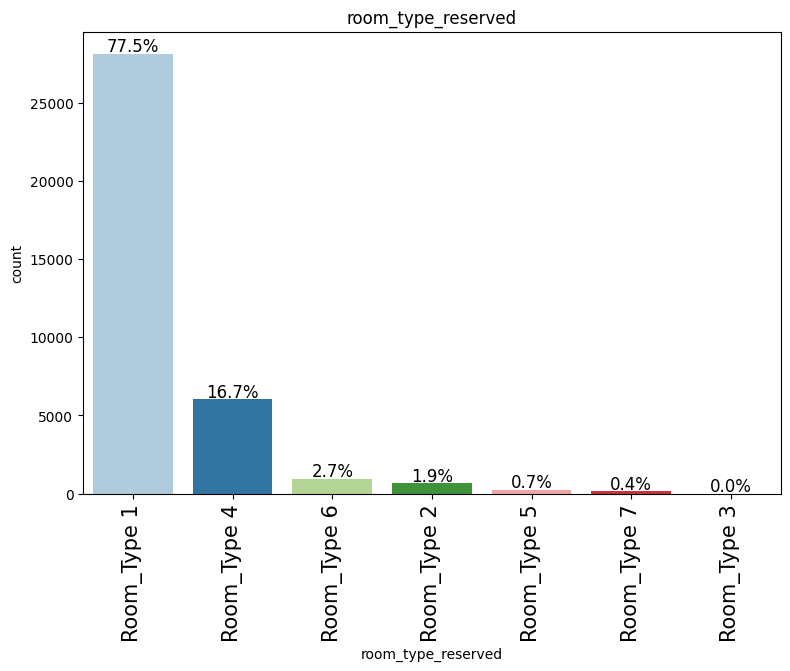

In [43]:
#visualize room type reserved
labeled_barplot(data, 'room_type_reserved', perc=True)

- Room type 1 is the most common booking with 77.5% followed by room type 4 with 16.7%
- The remaining room types each have under 3% of the total bookings
- Room type 3 only has 7 bookings
- It would be interesting to see the total number of each room type available in the hotel, which would provide some further insight into booking capacity per room type.

####Observations on arrival year

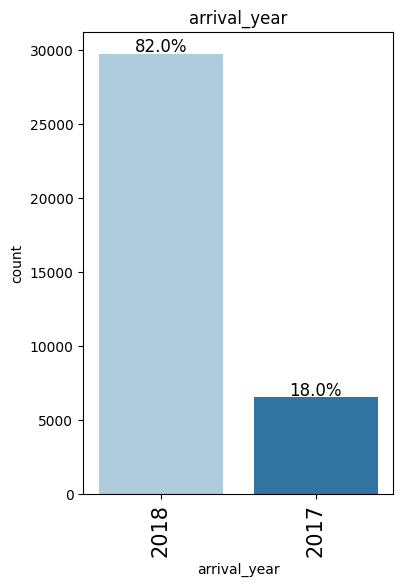

In [44]:
#visualize arrival year
labeled_barplot(data, 'arrival_year', perc=True)

- 82% of the data falls into the year 2018 while 18% of the data falls into 2017
- In terms of the scope of the problem, this isn't of much concern since we're looking at predicting cancellation, which is represented as a proportion of total bookings. However, we'll take a deeper look to understand the data set better.

In [45]:
#Checking the breakdown of data in collected in 2017
bookings_seventeen = data.loc[data['arrival_year']==2017]
bookings_seventeen['arrival_month'].value_counts()

10    1913
9     1649
8     1014
12     928
11     647
7      363
Name: arrival_month, dtype: int64

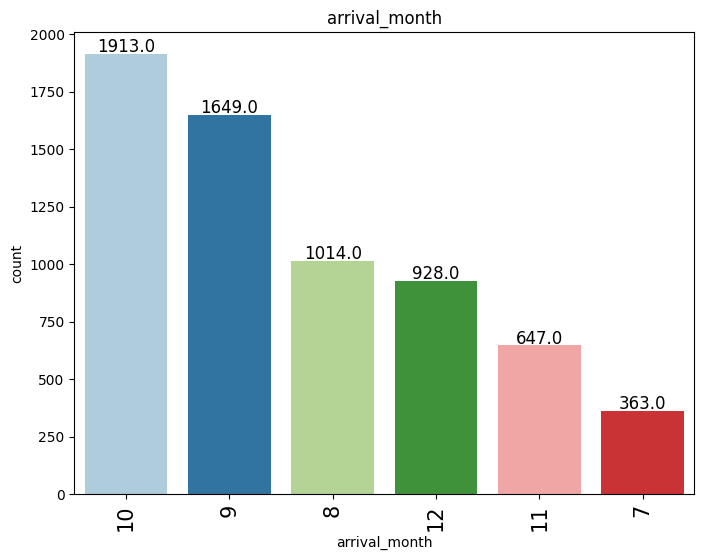

In [46]:
#Visualize bookings in 2017
labeled_barplot(bookings_seventeen, 'arrival_month')

- 2017 only accounts for 6 months of data from months 7-12
- In 2017 October (1913) is the busiest month, followed by September (1649) with July (363) being the least busy month

In [47]:
#Check how many rows belong in 2017
print('Number of bookings recorded in 2017 is' ,len(bookings_seventeen))

Number of bookings recorded in 2017 is 6514


In [48]:
#checking the data by month collected in 2018
bookings_eighteen = data.loc[data['arrival_year']==2018]
bookings_eighteen['arrival_month'].value_counts()

10    3404
6     3203
9     2962
8     2799
4     2736
5     2598
7     2557
3     2358
11    2333
12    2093
2     1704
1     1014
Name: arrival_month, dtype: int64

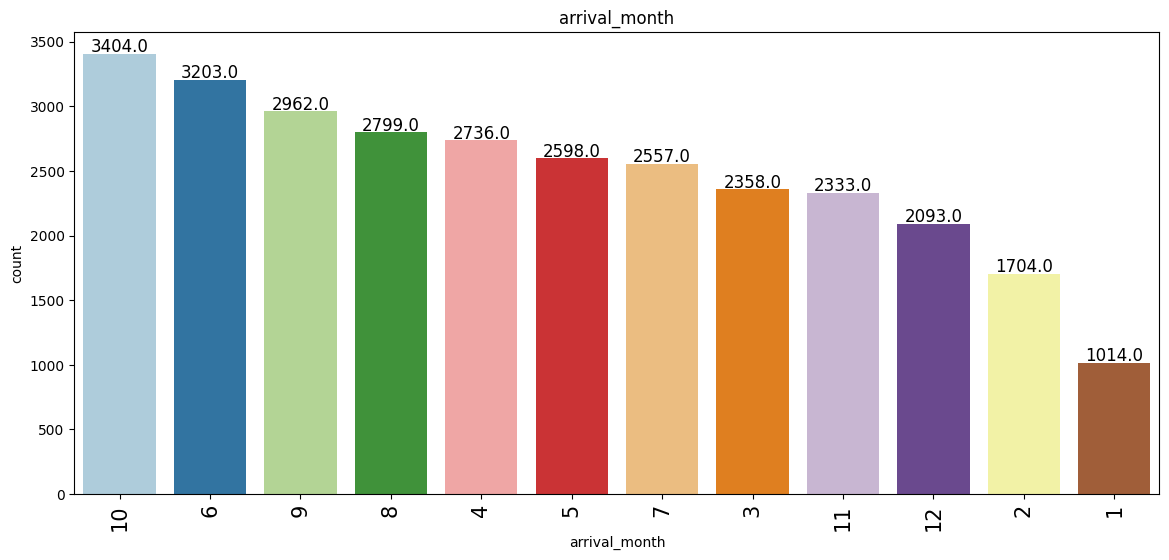

In [49]:
#Visualize bookings in 2018
labeled_barplot(bookings_eighteen, 'arrival_month')

- 2018 shows data from all 12 months of the year
- In 2018 October (3404) is the busiest month, followed by June (3203), then September (2962).
- The least busy months are January (1014) with the lowest followed by February (1704)
- As stated before this will not have a profound effect on the development of our model, but it is good to keep in mind that months 7 through 12 contain 2 calendar years worth of data while months 1-6 only have a single calendar year.

####Observations on arrival month

<Axes: xlabel='arrival_month', ylabel='Count'>

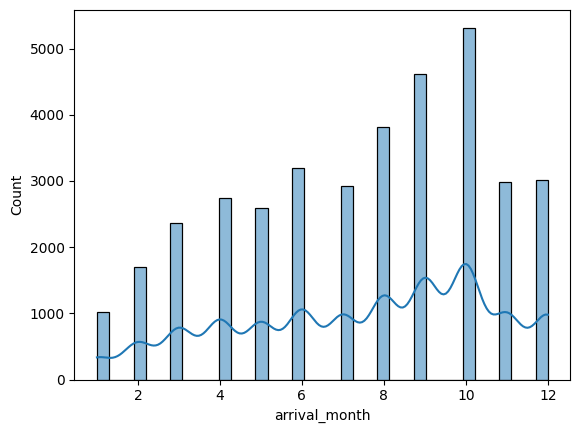

In [50]:
#visualize the distribution of arrivals throughout the year
sns.histplot(data=data, x='arrival_month', kde=True)

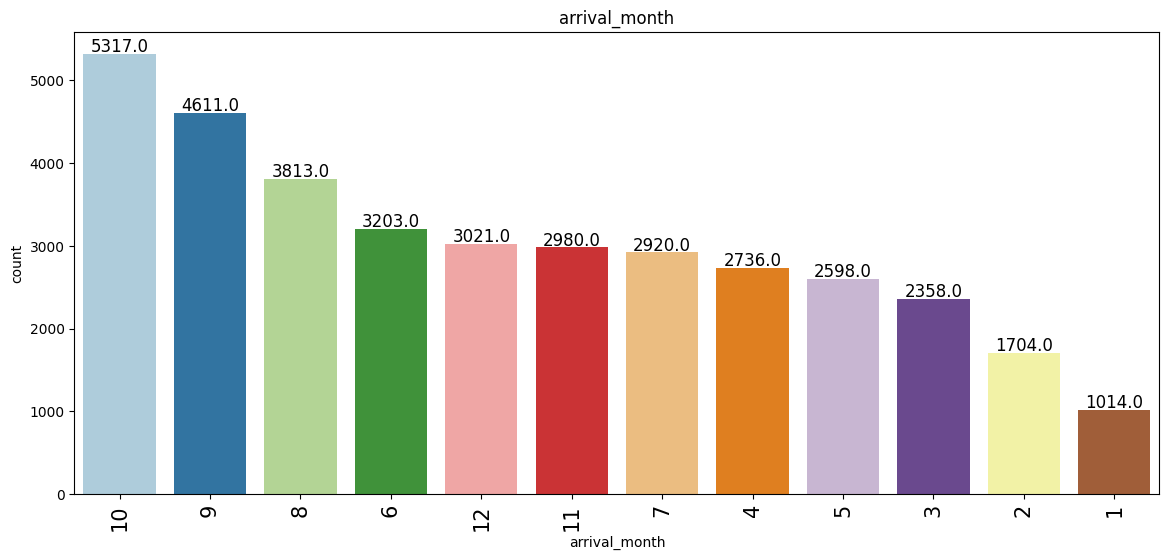

In [51]:
#visualize the count of arrivals for each month
labeled_barplot(data, 'arrival_month')

- The bookings generally increase month over month reaching its peak in october with a heavy drop in the winter months between November and February
- The busiest month in the hotel is october with 5317 bookings having arrived in october
- The least busy month is January with 1014 bookings
- The busiest time is in late summer through autumn, starting in august and capping in october

####Observations on arrival date

<Axes: xlabel='arrival_date', ylabel='Count'>

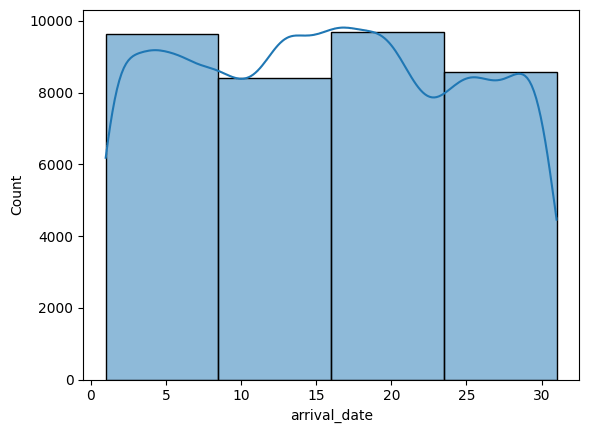

In [52]:
#visualize the distribution of arrivals
sns.histplot(data=data, x='arrival_date', kde=True, bins=4)

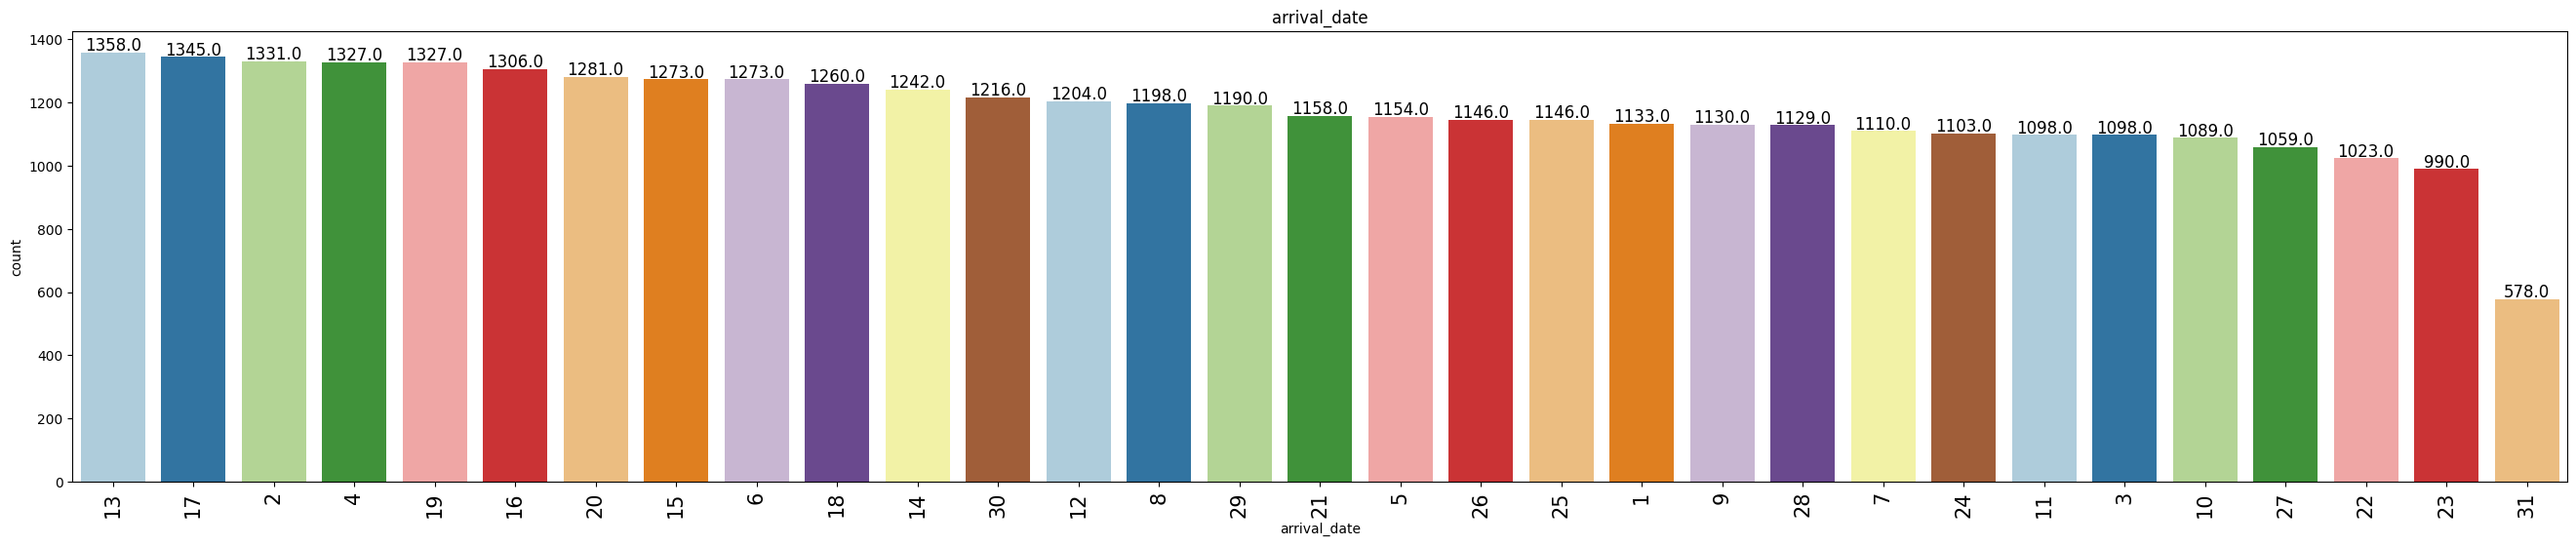

In [53]:
#visualize the count of arrivals on each day of the month
labeled_barplot(data, 'arrival_date')

- The arrival date is generally uniform with the expception of the 31st which makes sense because not every month has 31 days

- There does seem to be a higher instance of bookings in the 1st and 3rd week of each month in comparison to the 2nd and 4th week

####Observations on Market Segment


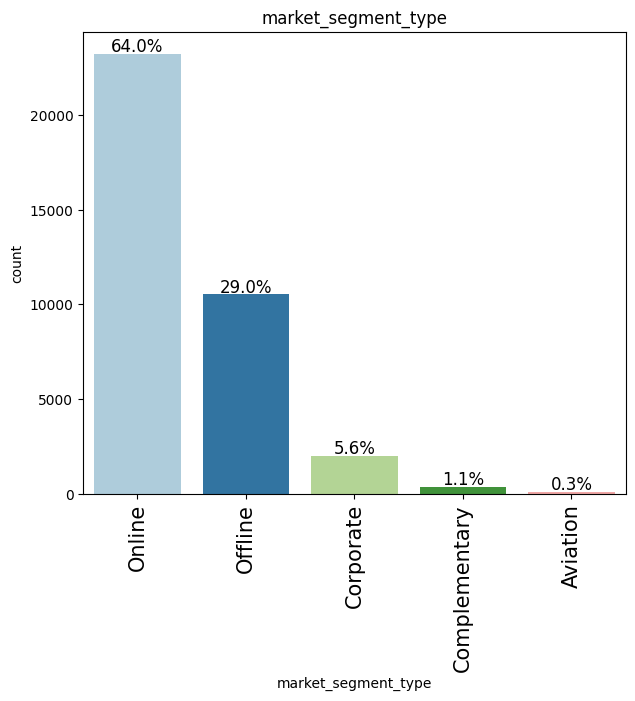

In [54]:
#visualize market segment type
labeled_barplot(data, 'market_segment_type', perc=True)

- Online is the most common making up 64% of all the bookings
- Offline is second with 29%
- Aviation has the least with .3%

####Observations on repeat guests

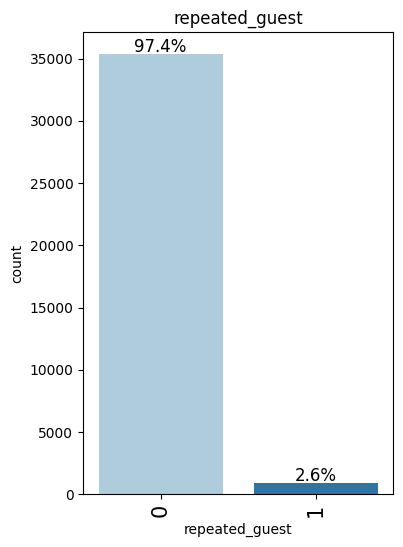

In [55]:
#visualize the distribution of arrivals throughout the year
labeled_barplot(data, 'repeated_guest', perc=True)

- Repeat guests make up 2.6% of the bookings, with most of the bookings, 97.4%, being first time guests

####Observations on number of special requests

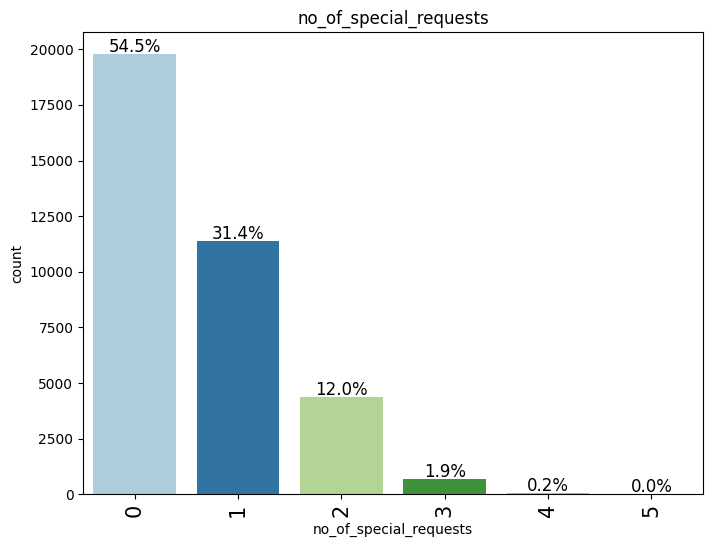

In [56]:
#visualize distibution of special requests
labeled_barplot(data, 'no_of_special_requests', perc=True)

- 54.5% dont make any special requests with the percentage decreasing as the number of requests increases.
- There are some instances with 5 special requests
- 31.4% make 1 special request

####Observations on booking status

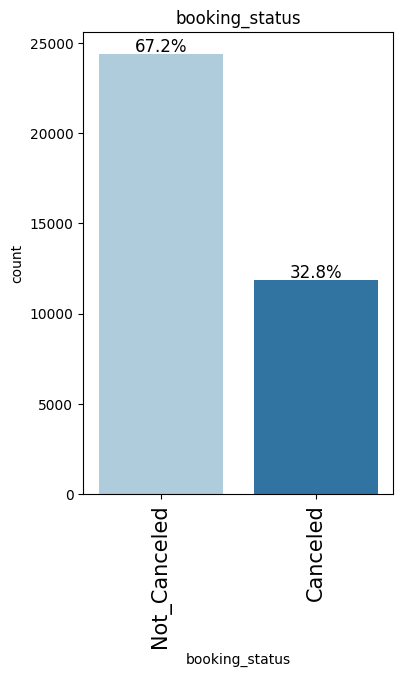

In [57]:
#visualize booking status
labeled_barplot(data, 'booking_status', perc=True)

- Nearly 1/3 of all bookings are cancelled (32.8%)

In [58]:
#change the booking status to numerical classifier
data['booking_status']= data['booking_status'].apply(
    lambda x:
    1 if x == 'Canceled'
    else 0
    )

data['booking_status'].dtype

dtype('int64')

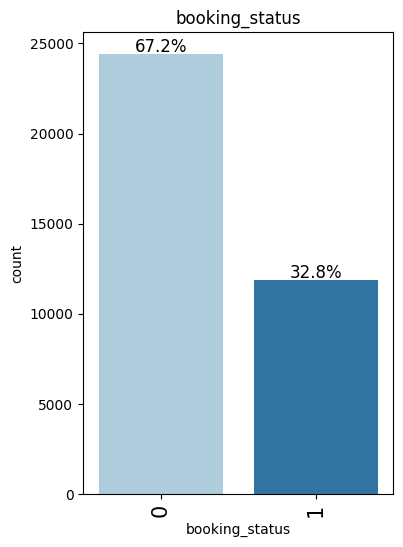

In [59]:
#Run visualization again to be sure the x-axis labels have changed
labeled_barplot(data, 'booking_status', perc=True)

- Dependent variable has been changed from an object to an integer to allow for modeling
- In creating the model we will treat 0 (negative) as a not-cancelled and 1 (postive) as cancelled

###Bivariate Analysis

In [60]:
#Set the numeric columns to a variable
cols_list = data.select_dtypes(include=np.number).columns.tolist()

cols_list

['no_of_adults',
 'no_of_children',
 'no_of_weekend_nights',
 'no_of_week_nights',
 'required_car_parking_space',
 'lead_time',
 'arrival_year',
 'arrival_month',
 'arrival_date',
 'repeated_guest',
 'no_of_previous_cancellations',
 'no_of_previous_bookings_not_canceled',
 'avg_price_per_room',
 'no_of_special_requests',
 'booking_status']

In [61]:
#check to be sure we have all the numeric variables, there should be 15
len(cols_list)

15

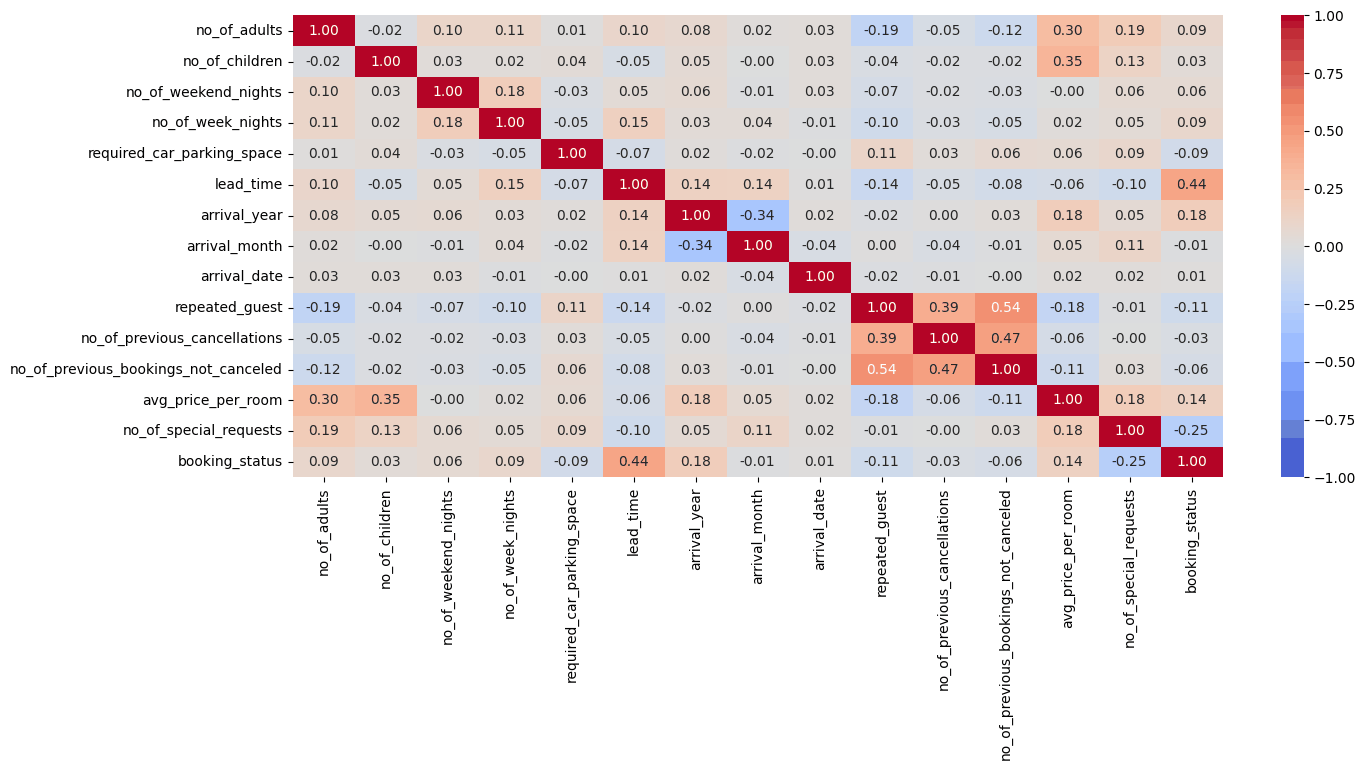

In [62]:
#Visualize heat map of numerical values
plt.figure(figsize=(15,6))
sns.heatmap(data[cols_list].corr(), annot=True, vmin= -1, vmax= 1, fmt='.2f',  cmap='coolwarm')
plt.show()


- In regards to the dependent variable, booking status lead time has the highest positive correlation (0.44) followed by arrival year (0.18) andaverage price per room(0.14).
- While the strongest negative correlations are number of special requests (-0.25), repeated guest(-0.11) and required parking spaces (-0.09)
- There aren't many strong correlations between independent variables, number of adults and children has the strongest postive correlation, .30 and .34, repectively to the average price, which makes sense, since more people would need a larger room.
- The aformentioned independent variables will be primary focus of the bivariate analysis.
- There are no significant cases of high correlation between variables observed

#### Market Segment Types vs Average Price per Room

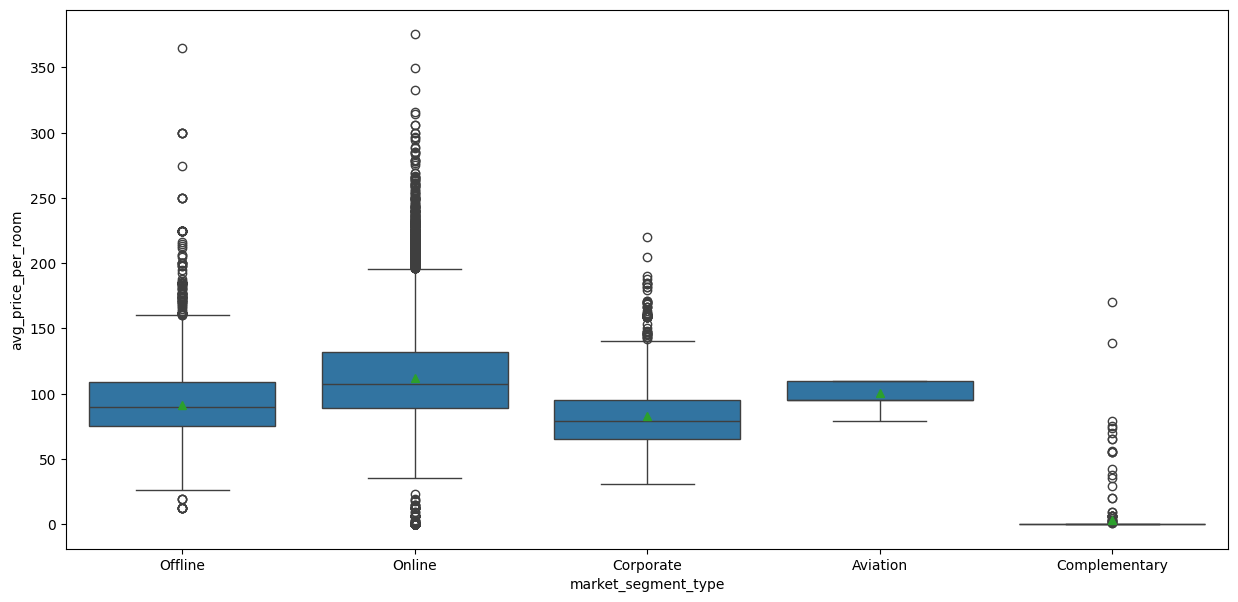

In [63]:
#visualize average price per room vs market segment type
plt.figure(figsize=(15, 7))
sns.boxplot(data=data, x='market_segment_type', y= 'avg_price_per_room', showmeans=True)
plt.show()

- The largest range of price is in the online booking, with prices ranging from 0 to over 350 Euros

- Aviation is the most uniform with the smallest range, likely due to an aviation rate

- complimentary has most of the values being 0, however there are average price per rooms, which can mean a partial complimentary stay occured where only a portion of the stay was comped

- Corporate bookings on avarage are the cheapest while Online is the the most expensive on avarage

- Offline on average is slightly cheaper than online bookings

####Market Segment Types vs Booking Status

booking_status           0      1    All
market_segment_type                     
All                  24390  11885  36275
Online               14739   8475  23214
Offline               7375   3153  10528
Corporate             1797    220   2017
Aviation                88     37    125
Complementary          391      0    391
------------------------------------------------------------------------------------------------------------------------


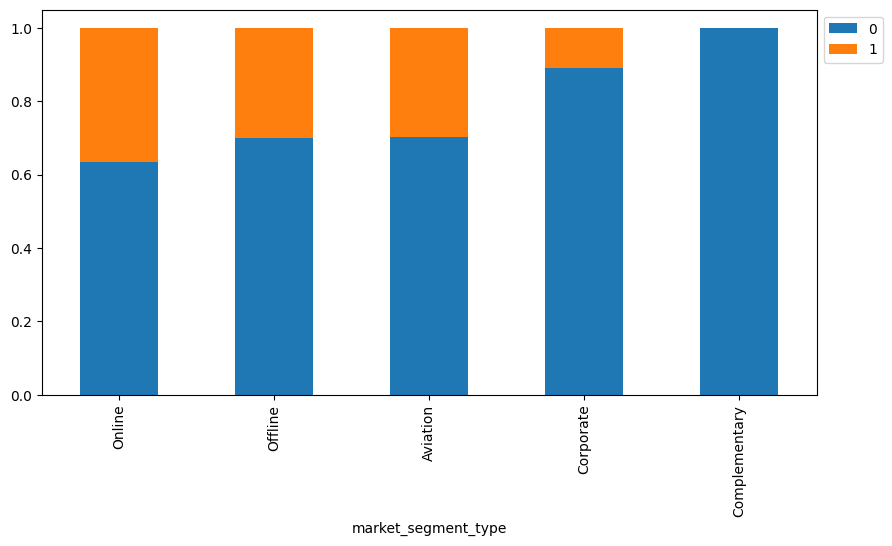

In [64]:
#market segment type vs booking status visualization
stacked_barplot(data, 'market_segment_type', 'booking_status')

- Complimentary has 0 cancellations while online has the most cancellations with ~35% cancelling
- Offline and Aviation are similar with ~30% cancelling
- Corporate has ~10% cancellation rate

#### Number of Special Requests vs Booking Status

booking_status              0      1    All
no_of_special_requests                     
All                     24390  11885  36275
0                       11232   8545  19777
1                        8670   2703  11373
2                        3727    637   4364
3                         675      0    675
4                          78      0     78
5                           8      0      8
------------------------------------------------------------------------------------------------------------------------


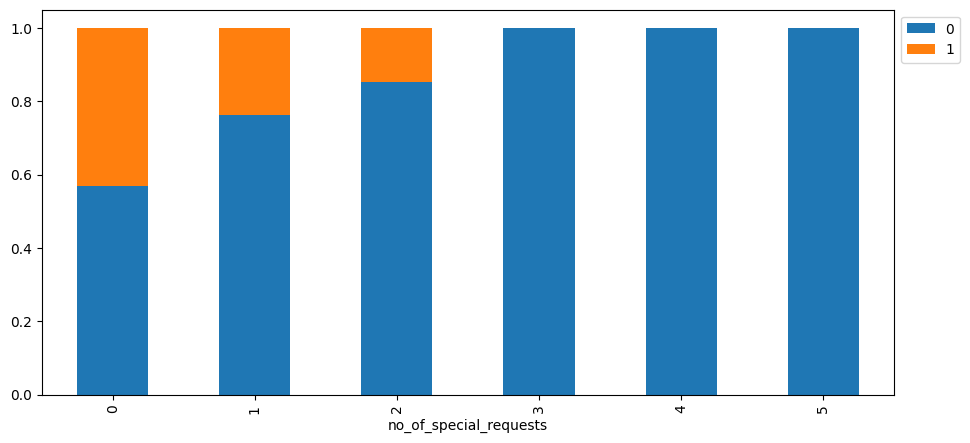

In [65]:
#visualizing number of special requests vs booking status
stacked_barplot(data, 'no_of_special_requests', 'booking_status')

- As the number of special requests increases the number of cancellations decreases with ~40% cancelling with no requests and no cancellations occuring with 3 or more requests
- 1 request has ~25% cancellations and 2 requests has ~15% cancellations

#### Number of Special Requests vs Room Price

<Axes: xlabel='no_of_special_requests', ylabel='avg_price_per_room'>

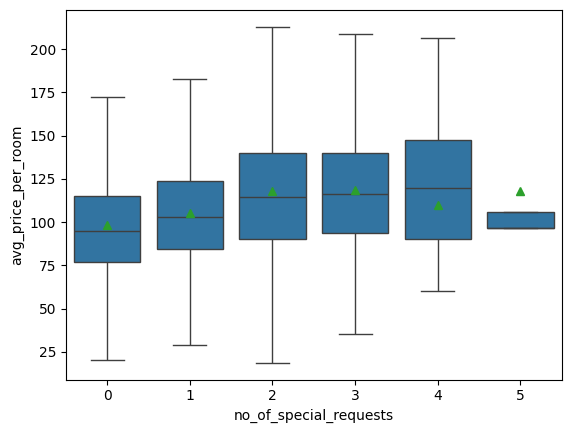

In [66]:
#visualize number of special requests vs avg price per room
sns.boxplot(data=data, x='no_of_special_requests' ,y= 'avg_price_per_room', showfliers=False, showmeans=True)

- The average price per room typically increases as the number of requests increases until it 4 requests is reached.

#### Repeat Guests vs Booking Status

booking_status      0      1    All
repeated_guest                     
All             24390  11885  36275
0               23476  11869  35345
1                 914     16    930
------------------------------------------------------------------------------------------------------------------------


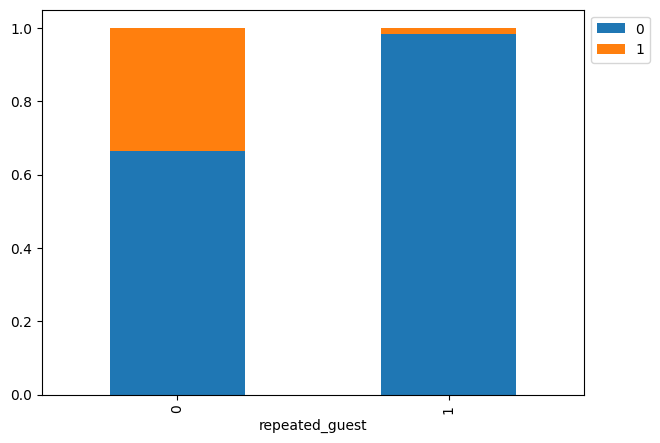

In [67]:
#visualizing number of repeat guests vs booking status
stacked_barplot(data, 'repeated_guest', 'booking_status')

In [68]:
#calculate the percentage or repeat guests who cancel
print('The percentage of repeat guests who cancel is',
      np.round((len(data.loc[(data['repeated_guest']==1) & (data['booking_status']==1)]) /len(data[data['repeated_guest']==1])) *100, 2), '%')

The percentage of repeat guests who cancel is 1.72 %


- A repeat guest is much less likely to cancel than a first time guest, reducing the cancellation percentage from ~35% to 1.72%

####Analysis of Average Prices per Room and Booking Status

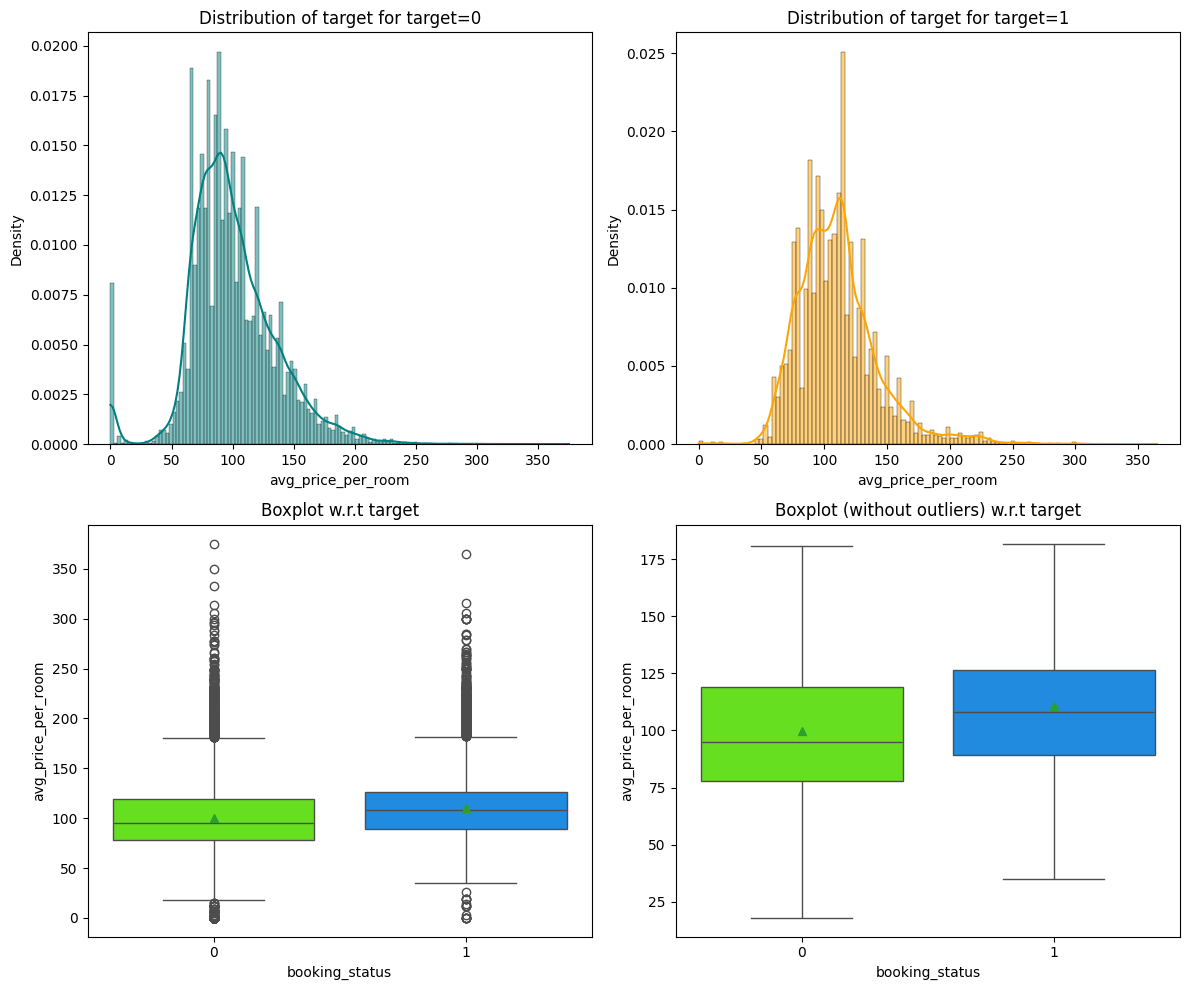

In [69]:
#visualize the room price with respect to booking status
distribution_plot_wrt_target(data, 'avg_price_per_room', 'booking_status')

- Guests who cancel generally have a higher price per room than those who don't cancel
- The average non cancellation is paying around ~100 Euros while the cancellation group is paying around ~115 Euros

####Analysis of Lead time on Booking Status

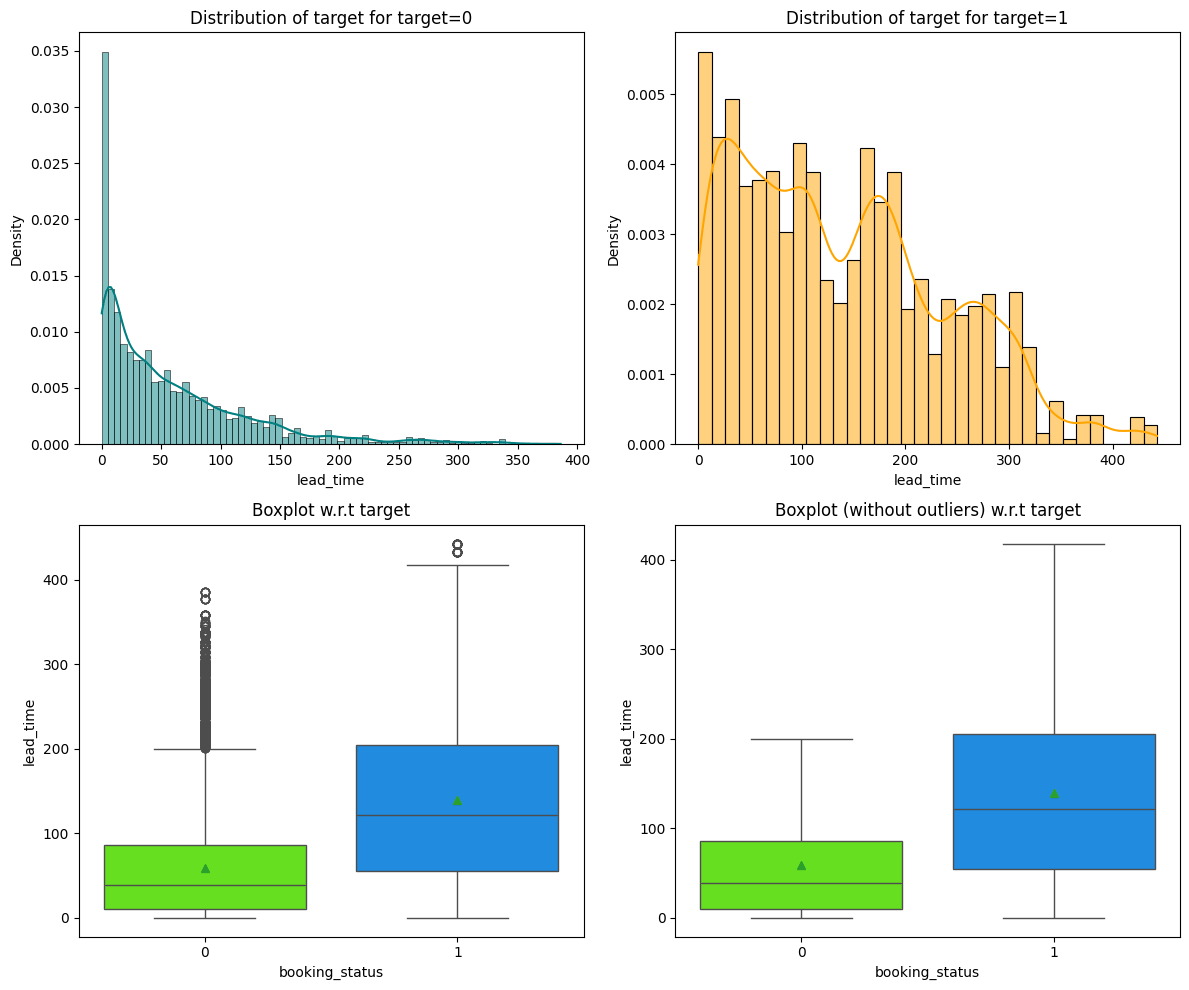

In [70]:
#visualize the lead time with respect to booking status
distribution_plot_wrt_target(data, 'lead_time', 'booking_status')

- Guests who don't cancel have a much shorter lead time than those who cancel
- The average lead time for a non cancelation is under a 100 days, while those who cancel have an average lead time close to 150 days

####Visualize total bookings in the data set

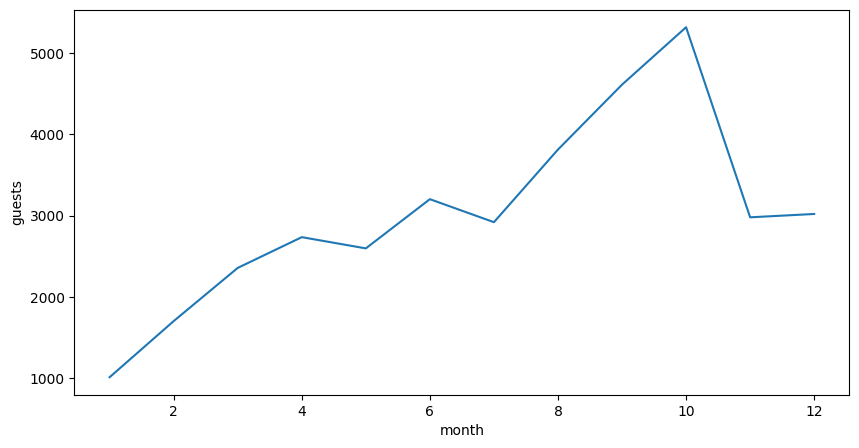

In [71]:
#Group data by month showing to show bookings per month
monthly_business = data.groupby(['arrival_month'])['booking_status'].count()
#Convert the data to a dataframe
monthly_business_df= pd.DataFrame(
    {'month': list(monthly_business.index), 'guests': list(monthly_business.values)})

#visualize bookings over each month
plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_business_df, x="month", y="guests")
plt.show()

booking_status      0      1    All
arrival_month                      
All             24390  11885  36275
10               3437   1880   5317
9                3073   1538   4611
8                2325   1488   3813
7                1606   1314   2920
6                1912   1291   3203
4                1741    995   2736
5                1650    948   2598
11               2105    875   2980
3                1658    700   2358
2                1274    430   1704
12               2619    402   3021
1                 990     24   1014
------------------------------------------------------------------------------------------------------------------------


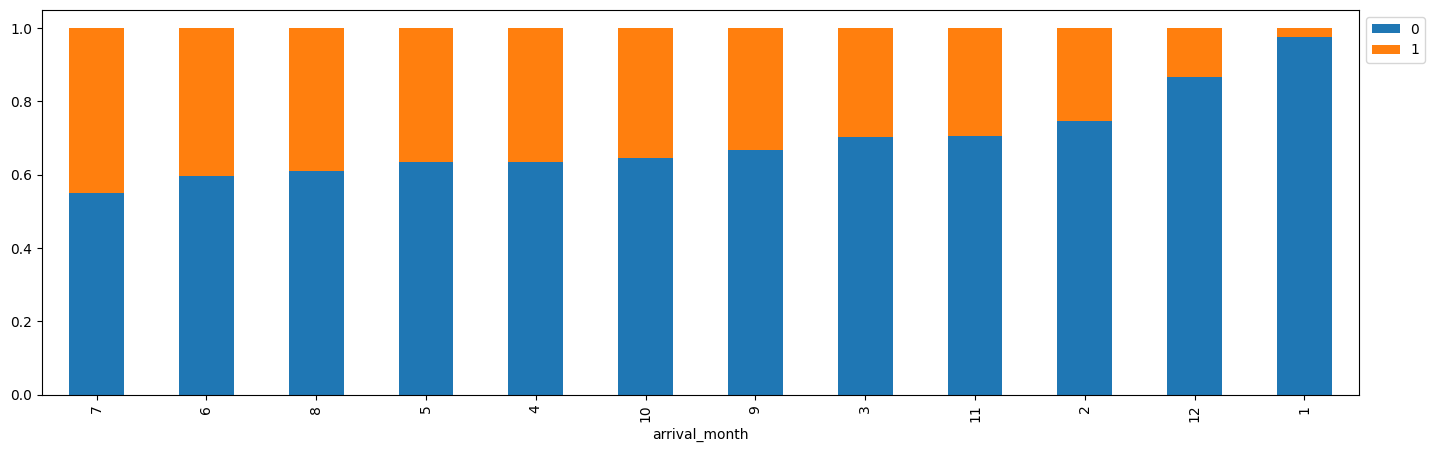

In [72]:
#visualize the percentage of cancellations in each month
stacked_barplot(data, 'arrival_month', 'booking_status')

- The summer months have the highest percentage of cancellations with the top 4 months being July, June, August, and May (Highest to lowest)
- The month with the lowest cancellation percentage is January

####Price per room vs Arrival Month

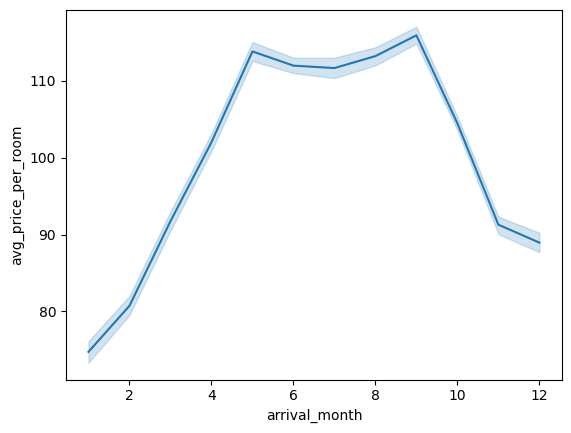

In [73]:
#visualize relationship between price and the month
sns.lineplot(data=data, x='arrival_month', y='avg_price_per_room')
plt.show()

- The cheapest month is January with an increase in price going through to May, the price genrally levels out with the peak being in september.

- The price decreases until through december and will drop more once returning to January

## Data Preprocessing

- Missing value treatment - No Missing Values present in the data
- Outlier detection and treatment- Treated during EDA, but will perform another check on variables to be sure

###Outlier Check and Treatment

Outlier treatment for avg price per room, number of children


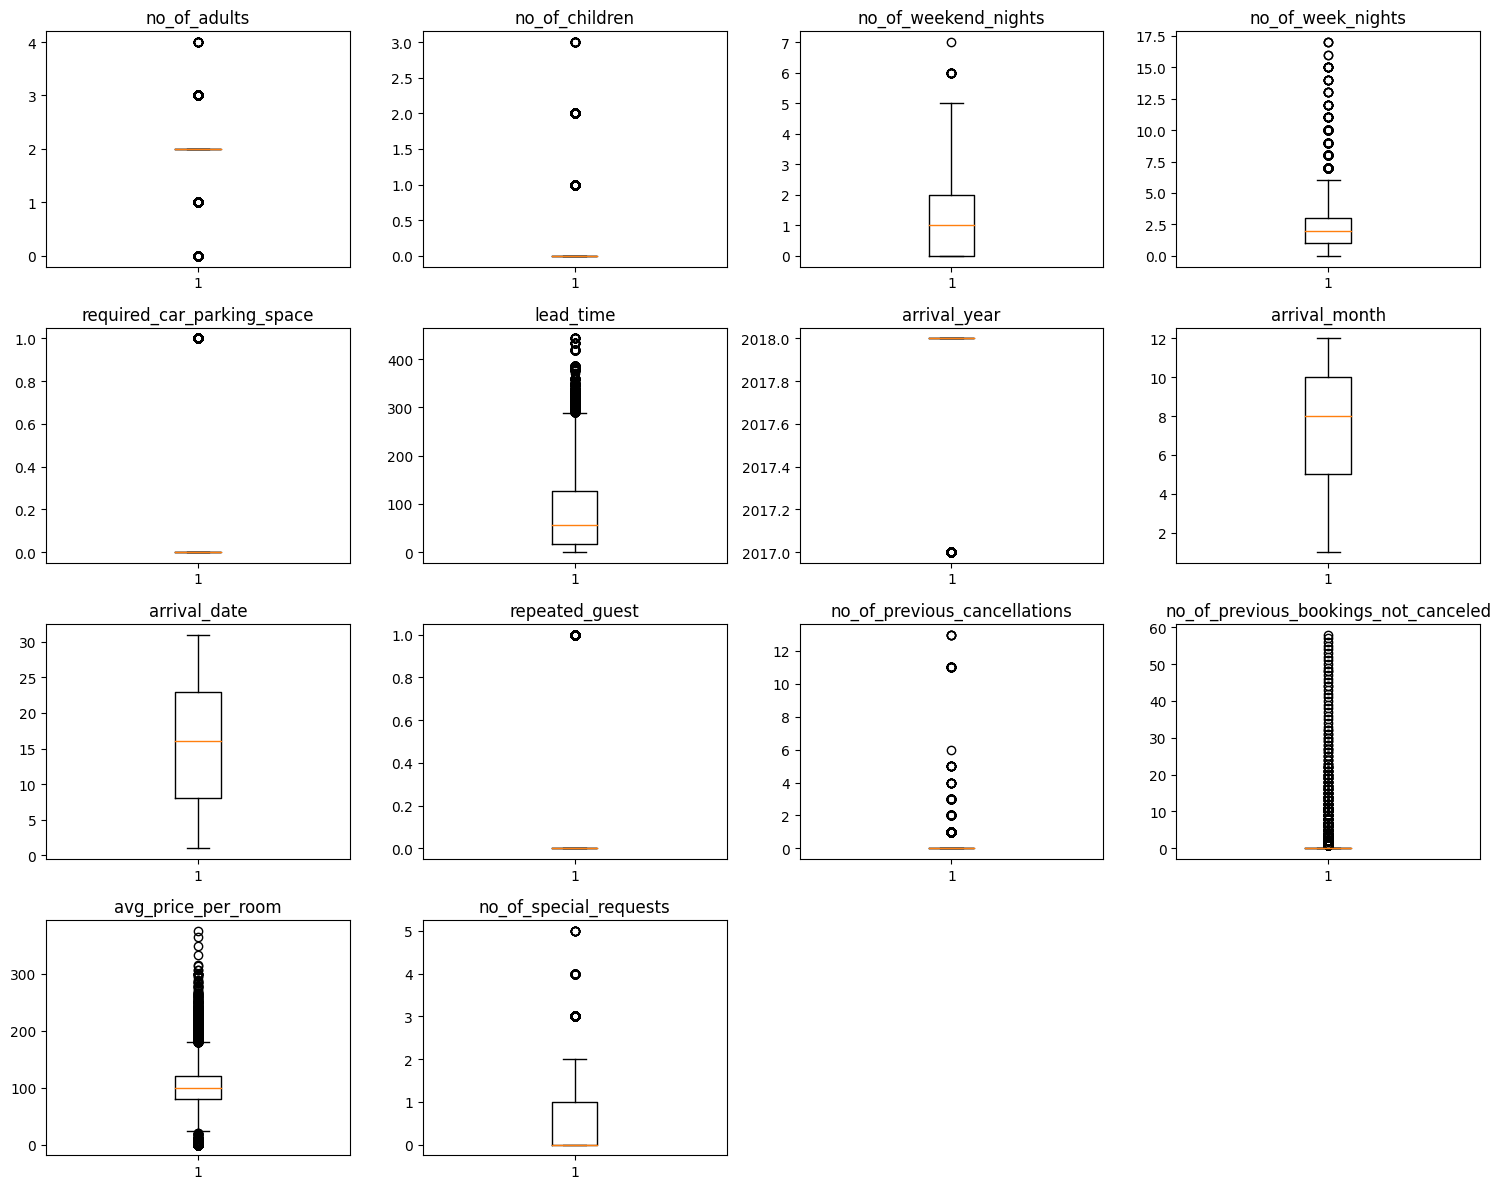

In [74]:
# outlier detection using boxplot
numeric_columns = cols_list
# dropping booking_status
numeric_columns.remove("booking_status")

plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(data[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

- The outliers which needed to be treated have been and the remaining data looks good to continue into preparation for modeling

## Model Evaluation Criterion

In context of the problem statement we are looking to predict booking cancelations. There are two types of errors we can encounter:

1. False Positive - Predicting the booking will cancel but in actuality they wont cancel.
2. Flase Negative - Predicting the booking will not cancel but in actuality they do cancel.

Which case is more important?

- Both cases can be considered important:

1. False Postive: If we predict a booking to cancel and they do not cancel, the overall guest experience can suffer due to a lack of resources and service capacity needed to provide a satisfactory stay.

2. False Negative: If we predict the booking to not cancel and the guest does cancel, the hotel is not filling the capacity and losing out on revenue with empty rooms and possible over staffing.

Which Metric Should we Optimize?

The F1 Score should be maximized for the hotel, since F1 considers 2 performance metrics; precision and recall reducing the instance of both false positives and false negatives.

##Model Building - Logistic Regression



###Define Functions Needed for Model Building

In [75]:
#defining function to compute a variety of metrics to check performance of a classification model
def model_performance_classification_statsmodels(model, predictors, target, threshold=0.5):
  """
  Function to compute different metrics to check classifcation model performance

  model: classifier
  predictors: independent variables
  target: dependent variables
  threshold: threshold for classifying observations as class 1
  """

  #checking which probablitilites are greater than threshold
  pred_temp = model.predict(predictors) > threshold
  #rounding off the above values to get classes
  pred= np.round(pred_temp)

  acc = accuracy_score(target, pred) #compute Accuracy
  recall = recall_score(target, pred) #compute Recall
  precision = precision_score(target, pred) #compute Precision
  f1 = f1_score(target, pred) #compute F1-Score

  #creating a dataframe for the metrics
  df_perf = pd.DataFrame(
      {'Accuracy': acc, 'Recall': recall, 'Precision': precision, 'F1':f1},index=[0]

  )

  return df_perf


In [76]:
#defining a function to plot the confusion matrix of a classification model


def confusion_matrix_statsmodels(model, predictors, target, threshold=0.5):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    threshold: threshold for classifying the observation as class 1
    """
    y_pred = model.predict(predictors) > threshold
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

###Preparing Data for Modeling

- The goal of the problem is to predict cancellation of bookings
- We'll be separating the data in to train and test sets with independent variables being set to "X" and dependent (target) variable 'booking_status' being set to "y"
- We'll be using a 70/30 split in respect to train/test on the data

In [77]:
#split data into independent and dependent variables
X = data.drop(['booking_status'], axis=1)
y = data['booking_status']

#add constant
X= sm.add_constant(X)

#creating dummie variables
X= pd.get_dummies(X, drop_first=True)

#splitting data in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.30, random_state=1, stratify= y
)

print(X.head())
print( "\n")
print('dependent variable\n', y.head())

    const  no_of_adults  no_of_children  no_of_weekend_nights  \
0 1.00000             2               0                     1   
1 1.00000             2               0                     2   
2 1.00000             1               0                     2   
3 1.00000             2               0                     0   
4 1.00000             2               0                     1   

   no_of_week_nights  required_car_parking_space  lead_time  arrival_year  \
0                  2                           0        224          2017   
1                  3                           0          5          2018   
2                  1                           0          1          2018   
3                  2                           0        211          2018   
4                  1                           0         48          2018   

   arrival_month  arrival_date  repeated_guest  no_of_previous_cancellations  \
0             10             2               0                    

In [78]:
data.shape

(36275, 18)

In [79]:
#check first five rows of X for dummies split
X.head()

,const,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,type_of_meal_plan_Meal Plan 2,type_of_meal_plan_Meal Plan 3,type_of_meal_plan_Not Selected,room_type_reserved_Room_Type 2,room_type_reserved_Room_Type 3,room_type_reserved_Room_Type 4,room_type_reserved_Room_Type 5,room_type_reserved_Room_Type 6,room_type_reserved_Room_Type 7,market_segment_type_Complementary,market_segment_type_Corporate,market_segment_type_Offline,market_segment_type_Online
0,1.00000,2,0,1,2,0,224,2017,10,2,0,0,0,65.00000,0,0,0,0,0,0,0,0,0,0,0,0,1,0
1,1.00000,2,0,2,3,0,5,2018,11,6,0,0,0,106.68000,1,0,0,1,0,0,0,0,0,0,0,0,0,1
2,1.00000,1,0,2,1,0,1,2018,2,28,0,0,0,60.00000,0,0,0,0,0,0,0,0,0,0,0,0,0,1
3,1.00000,2,0,0,2,0,211,2018,5,20,0,0,0,100.00000,0,0,0,0,0,0,0,0,0,0,0,0,0,1
4,1.00000,2,0,1,1,0,48,2018,4,11,0,0,0,94.50000,0,0,0,1,0,0,0,0,0,0,0,0,0,1


In [80]:
#check to see that the split worked correctly
print('X_train shape', X_train.shape)
print('X_test shape', X_test.shape)
print('y_train shape', y_train.shape )
print('y_test shape', y_test.shape)
print('Percentage of classes in test set:')
print(y_train.value_counts(normalize=True))
print('Percentage of classes in test set:')
print(y_test.value_counts(normalize=True))

X_train shape (25392, 28)
X_test shape (10883, 28)
y_train shape (25392,)
y_test shape (10883,)
Percentage of classes in test set:
0   0.67238
1   0.32762
Name: booking_status, dtype: float64
Percentage of classes in test set:
0   0.67233
1   0.32767
Name: booking_status, dtype: float64


- We see that the proportion of not cancelled (0) 67.2% and cancelled (1) 32.8% is preserved in both training and test sets.

###Build Intial Logistic Regression Model

- We will be performing a logistic regression using statsmodels to check the statistical validity of our model - identify the significant predictors from p-value that we get for each predictor variable.

In [81]:
#fitting logistic regression model
logit= sm.Logit(y_train, X_train.astype(float))
lg= logit.fit()

#print the model
print(lg.summary())

         Current function value: 0.422404
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25392
Model:                          Logit   Df Residuals:                    25364
Method:                           MLE   Df Model:                           27
Date:                Sun, 03 Mar 2024   Pseudo R-squ.:                  0.3321
Time:                        00:25:26   Log-Likelihood:                -10726.
converged:                      False   LL-Null:                       -16060.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
const                                 -886.9564    121.335     -7.310      0.000   -1124.769

- The coefficients of the logistic regression model are in terms of log(odd).


Observations
- Negative values of the coefficient show the probability of a booking cancelling will decrease with the increase of the corresponding attribute value
- Positive values of the coefficient show the probability of a booking cancelling will increase with the increase of the corresponding attribute value
- p-value of a variable indicates if the variables is significant or not, p-values < 0.05 are deemed to be significant. We can see instances of p-values being > 0.05

####Checking the Performance of the Intial Model

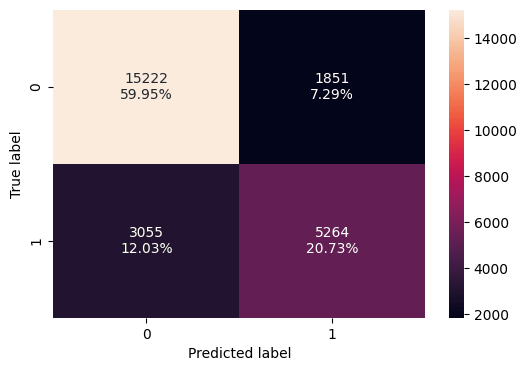

In [82]:
#Checking confusion matrix on the training set
confusion_matrix_statsmodels(lg, X_train, y_train)

In [83]:
#Checking the model performance on the training set
model_performance_classification_statsmodels(lg, X_train, y_train)

,Accuracy,Recall,Precision,F1
0,0.80679,0.63277,0.73985,0.68213


Observations

- The f1 score of the model is ~0.68 which we will try to maximize
- The variables used in building the model may contain multicollinearity which we will look into
- Removing features with high multicollinearity from the model will improve the reliability of the remaining features

### Checking Multicollinearity

- In order to make statistical inferences from a logistic regression model, it is important to ensure that there is no multicollinearity present in the data.

- Variance Inflation Factor
  - This test will compute the VIF which tests for multicollinearity
  General Rule of thumb:

    - If VIF is 1 then there is no correlation between the $k$th predictor and the remaining predictor variables.
    - If VIF exceeds 5 or is close to exceeding 5, we say there is moderate multicollinearity.
    - If VIF is 10 or exceeding 10, it shows signs of high multicollinearity.
  - We will address columns showing strong (VIF > 10) and moderate (VIF > 5) multicollinearity

In [84]:
#start by defining VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor

def checking_vif(predictors):
  vif=pd.DataFrame()
  vif['feature']=predictors.columns

  #calculating VIF for each feature
  vif['VIF']= [
      variance_inflation_factor(predictors.values, i)
      for i in range (len(predictors.columns))
  ]

  return vif

In [85]:
checking_vif(X_train).sort_values(by='VIF', ascending=False)


,feature,VIF
0,const,39624634.31385
27,market_segment_type_Online,69.47432
26,market_segment_type_Offline,62.51418
25,market_segment_type_Corporate,16.63449
24,market_segment_type_Complementary,4.35263
2,no_of_children,2.08820
13,avg_price_per_room,2.05023
22,room_type_reserved_Room_Type 6,2.04832
10,repeated_guest,1.75027
12,no_of_previous_bookings_not_canceled,1.57089


- There are 3 columns with VIF greater than 10 which indicates the presence of strong multicollinearity

Removing Multicollinearty
- We will drop every column one by one with VIF scores greater than 5
- Before dropping we will check to see if dropping a column will have a drastic reduction in adjusted r squared.
- We will conduct another VIF check after dropping each variable to reassess the targets and needs for removal of variables
- Once all remaining VIF's < 5 we can continue on.

market_segment_type_Online has the highest multicollinearity

Normally we would drop market segment type Online, since it has the highest VIF, however, when doing so it produces a 'singular matrix error' which doesn't allow us to proceed.

We will then drop the next higest VIF market_segment_type_Offline to remedy the 'singular matrix error'

In [86]:
#dropping high VIF
X_train1 = X_train.drop("market_segment_type_Offline", axis=1)
#checking VIF of remaining variables
checking_vif(X_train1).sort_values(by='VIF', ascending=False)


,feature,VIF
0,const,39507421.88089
2,no_of_children,2.08779
13,avg_price_per_room,2.04986
22,room_type_reserved_Room_Type 6,2.04808
26,market_segment_type_Online,1.78220
10,repeated_guest,1.74754
12,no_of_previous_bookings_not_canceled,1.57049
25,market_segment_type_Corporate,1.53226
7,arrival_year,1.43049
6,lead_time,1.39421


Dropping market segment type offline has treated all the Multicollienearity from the model without creating a 'singular matrix error'

In [87]:
#Creating a new regression model with VIF removed
lg1 = sm.Logit(y_train, X_train1.astype(float)).fit()

#checking the performance of the original model to the performance of the new model
print('pre VIF Treatment')
print( model_performance_classification_statsmodels(lg, X_train, y_train))
print('post VIF Treatment')
print( model_performance_classification_statsmodels(lg1, X_train1, y_train))

         Current function value: 0.423091
         Iterations: 35
pre VIF Treatment
   Accuracy  Recall  Precision      F1
0   0.80679 0.63277    0.73985 0.68213
post VIF Treatment
   Accuracy  Recall  Precision      F1
0   0.80636 0.63193    0.73917 0.68136


Observations

- We can see a marginal change in the performance of the model with small drops in each metric

- The F1 score reduced from .68213 to .68136 which is not a significant decrease

- We are clear to proceed with the model

### High P-Value Treatment

- Now that we've treated multicollinearity we can now address the p-values of predictor variables to check their significance.

Null Hypothesis: Independent feature is not significant

Alternative Hypothesis: Independent feature is that it is significant

- If the feature is not deemed significant (p-value > .05) then it can be removed from the model.

In [88]:
# initial list of columns
cols = X_train1.columns.tolist()

# setting an initial max p-value
max_p_value = 1

while len(cols) > 0:
    # defining the train set
    X_train_aux = X_train1[cols]

    # fitting the model
    model = sm.Logit(y_train, X_train_aux).fit(disp=False)

    # getting the p-values and the maximum p-value
    p_values = model.pvalues
    max_p_value = max(p_values)

    # name of the variable with maximum p-value
    feature_with_p_max = p_values.idxmax()

    if max_p_value > 0.05:
        cols.remove(feature_with_p_max)
    else:
        break

selected_features = cols
print(selected_features)

['const', 'no_of_weekend_nights', 'no_of_week_nights', 'required_car_parking_space', 'lead_time', 'arrival_year', 'arrival_month', 'repeated_guest', 'no_of_previous_cancellations', 'avg_price_per_room', 'no_of_special_requests', 'type_of_meal_plan_Meal Plan 2', 'type_of_meal_plan_Not Selected', 'room_type_reserved_Room_Type 2', 'room_type_reserved_Room_Type 4', 'room_type_reserved_Room_Type 5', 'room_type_reserved_Room_Type 6', 'room_type_reserved_Room_Type 7', 'market_segment_type_Corporate', 'market_segment_type_Online']


In [89]:
#adjusting the training variables to include only significat attributes
X_train2 = X_train1[selected_features]

In [90]:
lg2 = sm.Logit(y_train, X_train2.astype(float)).fit()

print(lg2.summary())

Optimization terminated successfully.
         Current function value: 0.423443
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25392
Model:                          Logit   Df Residuals:                    25372
Method:                           MLE   Df Model:                           19
Date:                Sun, 03 Mar 2024   Pseudo R-squ.:                  0.3305
Time:                        00:25:33   Log-Likelihood:                -10752.
converged:                       True   LL-Null:                       -16060.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                           -910.2028    120.826     -7.533    

- All p-values greater than .05 have been removed

- With multicollinearity and high p-values being treated we can consider X_train2 as the final attributes in the model with lg2 being the final model

### Coefficient Interpretations



- Negative values of the coefficient show the probability of a booking cancelling will decrease with the increase of the corresponding attribute value
- Positive values of the coefficient show the probability of a booking cancelling will increase with the increase of the corresponding attribute value

### Converting Coefficients to Odds

* The coefficients ($\beta$s) of the logistic regression model are in terms of $log(odds)$ and to find the odds, we have to take the exponential of the coefficients
* Therefore, **$odds =  exp(\beta)$**
* The percentage change in odds is given as $(exp(\beta) - 1) * 100$

In [91]:
#converting coefficients to odds
odds= np.exp(lg2.params)

#finding the percentage change
perc_change_odds = (np.exp(lg1.params)-1) *100

#removing limit from number of columns to display
pd.set_option('display.max_columns', None)

#adding the odds to a dataframe
pd.DataFrame({'Odds': odds, 'Change_odd%': perc_change_odds}, index=X_train2.columns).T

,const,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,repeated_guest,no_of_previous_cancellations,avg_price_per_room,no_of_special_requests,type_of_meal_plan_Meal Plan 2,type_of_meal_plan_Not Selected,room_type_reserved_Room_Type 2,room_type_reserved_Room_Type 4,room_type_reserved_Room_Type 5,room_type_reserved_Room_Type 6,room_type_reserved_Room_Type 7,market_segment_type_Corporate,market_segment_type_Online
Odds,0.00000,1.16411,1.03962,0.20154,1.01580,1.56659,0.95370,0.04987,1.32490,1.01886,0.22645,1.18024,1.22061,0.68959,0.77623,0.50560,0.48665,0.27547,2.36546,5.71879
Change_odd%,-100.00000,16.22294,3.96465,-79.85994,1.57544,57.35847,-4.55004,-84.80926,40.61215,1.86146,-77.39294,18.14665,22.08215,-33.29199,-22.19555,-49.59686,-55.65446,-73.73836,138.20269,467.08800


Coefficient Interpretations
- no_of_weekend_nights: Holding all other features constant a 1 unit increase in no_of_weekend_nights will increase the odds of cancelling by ~1.16 times or a ~16% increase in odds of cancelling.

- no_of_week_nights: Holding all other features constant a 1 unit increase in no_of_week_nights will increase the odds of cancelling by ~1.04 times or a ~4% increase in odds of cancelling.

- required_car_parking_space: Holding all other features constant a required_car_parking_space will decrease the odds of cancelling by ~0.2 times or a ~80% decrease in odds of cancelling over no required car parking space .

- lead_time: Holding all other features constant a 1 unit increase in lead_time will increase the odds of cancelling by ~1.02 times or a ~1.58% increase in odds of cancelling.

- arrival_year: Holding all other features constant a 1 unit increase in arrival_year will increase the odds of cancelling by ~1.6 times or a ~57% increase in odds of cancelling.

- arrival_month: Holding all other features constant a 1 unit increase in arrival_month will decrease the odds of cancelling by ~0.95 times or a ~4.5% decrease in odds of cancelling.

- repeated_guest: Holding all other features constant a repeated_guest will decrease the odds of cancelling by ~0.05 times or a ~84% decrease in odds of cancelling over a non-repeat guest.

- no_of_previous_cancellations: Holding all other features constant a 1 unit increase in no_of_previous_cancellations will increase the odds of cancelling by ~1.3 times or a ~41% increase in odds of cancelling.

- avg_price_per_room: Holding all other features constant a 1 unit increase in avg_price_per_room will increase the odds of cancelling by ~1.01 times or a
 ~1.86% increase in odds of cancelling.

- no_of_special_requests: Holding all other features constant a 1 unit increase in no_of_special_requests will decrease the odds of cancelling by ~0.23 times or a ~77% decrease in odds of cancelling.

- type_of_meal_plan: The odds of cancelling with Meal Plan 2 selected is ~1.18 times more than Meal Plan 1 or Meal Plan 3; or ~ 18% more odds than Meal Plan 1 or Meal Plan 3. Similarly, the odds of cancelling with Meal Plan Not Selected is ~1.22 times more than Meal Plan 1 or Meal Plan 3; or ~ 22% more odds than Meal Plan 1 or Meal Plan 3 [the dropped categories Meal Plan 1 and Meal Plan 3 are taken as a reference level]

- room_type_reserved: The odds of cancelling with Room_Type_2 selected is ~0.69 times less than Room_Type_1 or Room_Type_3 ; or ~ 33% fewer odds than Room_Type_1 or Room_Type_3. Similarly, the odds of cancelling with Room_Type_4 selected is ~0.77 times less than Room_Type_1 or Room_Type_3 ; or ~ 22% fewer odds than Room_Type_1 or Room_Type_3. Similarly, the odds of cancelling with Room_Type_5 selected is ~0.51 times less than Room_Type_1 or Room_Type_3 ; or ~ 50% fewer odds than Room_Type_1 or Room_Type_3. Similarly, the odds of cancelling with Room_Type_6 selected is ~0.49 times less than Room_Type_1 or Room_Type_3 ; or ~ 56% fewer odds than Room_Type_1 or Room_Type_3. Similarly, the odds of cancelling with Room_Type_7 selected is ~0.28 times less than Room_Type_1 or Room_Type_3 ; or ~ 74% fewer odds than Room_Type_1 or Room_Type_3
[the dropped categories Room_Type_1 and Room_Type_3 are taken as a refence level]

- market_segment_type: The odds of cancelling with Corporate market segment type is ~2.37 times more than Aviation, Complimentary or Offline; or ~ 138% more odds than Aviation, Complimentary or Offline market segment types. Similarly, the odds of cancelling with Corporate market segment type is ~5.72 times more than Aviation, Complimentary or Offline; or ~ 467% more odds than Aviation, Complimentary or Offline market segment types
[the dropped categories Aviation, Complimentary, and Offline are taken as a reference level]


###Model performance Check

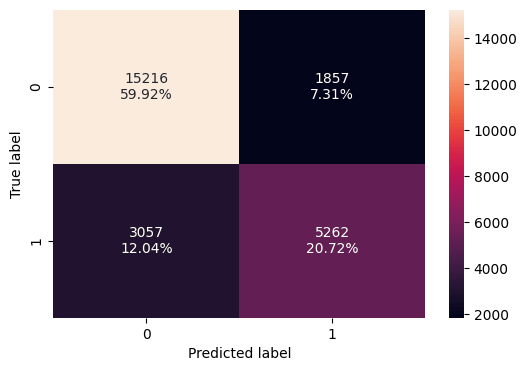

In [92]:
#confusion matrix on log regression for training set
confusion_matrix_statsmodels(lg2, X_train2, y_train)

In [93]:
#comparison of original model and model treated for multicollinearity and high p-values
print('original-train')
print( model_performance_classification_statsmodels(lg, X_train, y_train))
print('final-train')
print( model_performance_classification_statsmodels(lg2, X_train2, y_train))

original-train
   Accuracy  Recall  Precision      F1
0   0.80679 0.63277    0.73985 0.68213
final-train
   Accuracy  Recall  Precision      F1
0   0.80647 0.63253    0.73915 0.68169


- We can see a marginal change in the performance of the model with small drops in each metric

- The F1 score reduced from .68213 to .68169 which is not a significant decrease

- We will consider the features in X_train2 as the final features and lg2 as the final model

In [94]:
#train performance and set to variable for later comparison with auc-roc and optimal f1 thresholds
log_reg_model_train_perf = model_performance_classification_statsmodels(lg2, X_train2, y_train)
print('Training Performance')
log_reg_model_train_perf

Training Performance


,Accuracy,Recall,Precision,F1
0,0.80647,0.63253,0.73915,0.68169


Test Set Performance
- First we need to drop the same test set columns that we dropped in the training set

In [95]:
#Set test columns to X_train2 columns
X_test2 = X_test[list(X_train2.columns)]

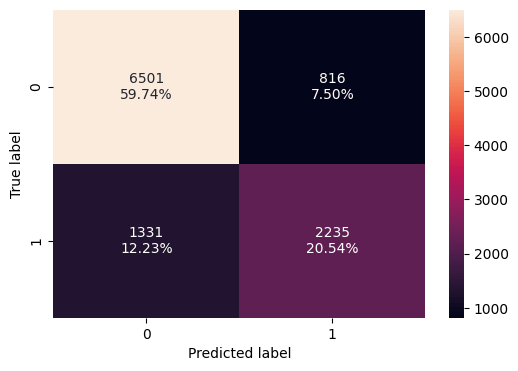

In [96]:
#confusion matrix on log regression for test set
confusion_matrix_statsmodels(lg2, X_test2, y_test)

In [97]:
#test performance and set to variable for later comparison with adjusted thresholds
log_reg_model_test_perf = model_performance_classification_statsmodels(lg2, X_test2, y_test)
print('Test Performance')
log_reg_model_test_perf

Test Performance


,Accuracy,Recall,Precision,F1
0,0.80272,0.62675,0.73255,0.67553


- The model is giving an f1_score of ~.682 and ~.676 on the train and test sets respectively
- The train and test performances are comparable which means the model is not overfitting
- We will work on improving the f1_score by adjusting the threshold

###Model Performance Improvement

- Let's see if the f1_score can be improved by changing the model threshold
- First, we will check the ROC curve, compute the area under the ROC curve (ROC-AUC), and then use it to find the optimal threshold
-Next, we will check the Precision-Recall curve to find the right balance between precision and recall as our metric of choice is f1_score

####ROC-Curve and ROC-AUC

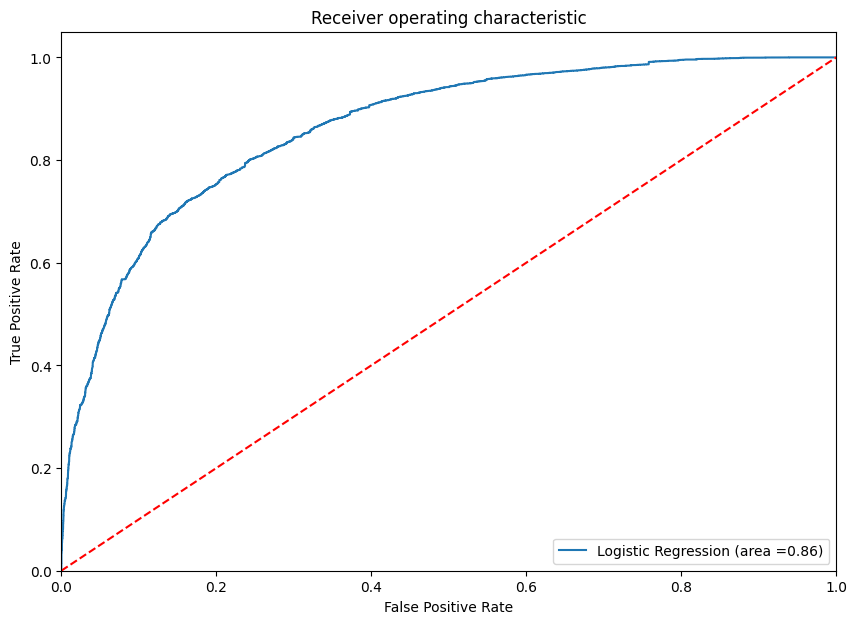

In [98]:
logit_roc_auc_train = roc_auc_score(y_train, lg2.predict(X_train2))
fpr, tpr, thresholds = roc_curve(y_train, lg2.predict(X_train2))
plt.figure(figsize= (10,7))
plt.plot(fpr, tpr, label= 'Logistic Regression (area =%0.2f)'% logit_roc_auc_train)
plt.plot([0, 1], [0, 1], "r--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver operating characteristic")
plt.legend(loc="lower right")
plt.show()

Logistic Regression Model is performing well on the training set

####Optimal Threshold using AUC-ROC curve

In [99]:
#Optimal cut off is where tpr is high and fpr is low
fpr, tpr, thresholds = roc_curve(y_train, lg2.predict(X_train2))

optimal_idx = np.argmax(tpr-fpr)
optimal_threshold_auc_roc = thresholds[optimal_idx]
print(optimal_threshold_auc_roc)

0.3265173651868932


Checking Model Performance on the Training Set

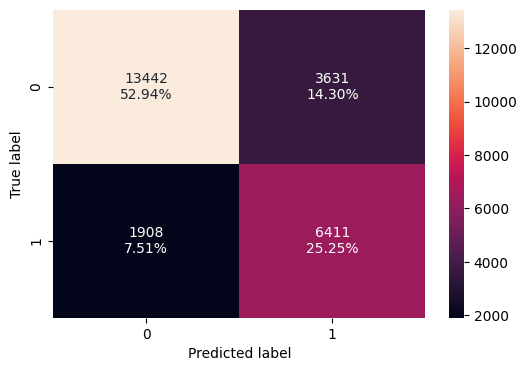

In [100]:
#creating a confusion matrix using optimal auc-roc threshold
confusion_matrix_statsmodels(lg2, X_train2, y_train, threshold=optimal_threshold_auc_roc)

In [101]:
#checking model performance for the model with optimum threshold
log_reg_model_train_perf_threshold_auc_roc = model_performance_classification_statsmodels(lg2, X_train2, y_train, threshold=optimal_threshold_auc_roc)

print('Training performance with optimal auc-roc threshold')
print(log_reg_model_train_perf_threshold_auc_roc)

Training performance with optimal auc-roc threshold
   Accuracy  Recall  Precision      F1
0   0.78186 0.77065    0.63842 0.69833


- The Recall and F1 scores have increased but the Accuracy and Precision have decreased

- The model is still performing well

Checking model performance on test set

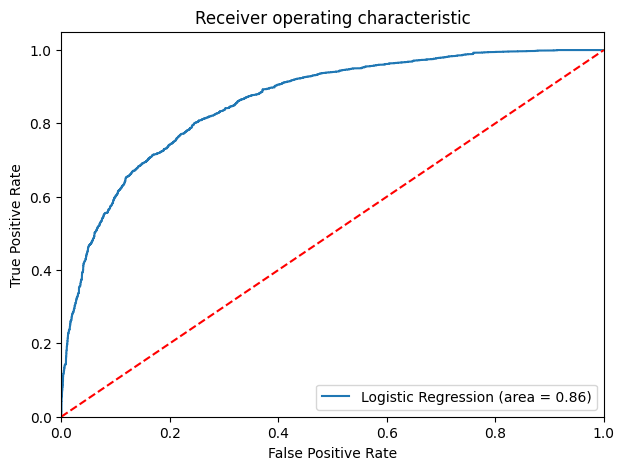

In [102]:
logit_roc_auc_train = roc_auc_score(y_test, lg2.predict(X_test2))
fpr, tpr, thresholds = roc_curve(y_test, lg2.predict(X_test2))
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label="Logistic Regression (area = %0.2f)" % logit_roc_auc_train)
plt.plot([0, 1], [0, 1], "r--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver operating characteristic")
plt.legend(loc="lower right")
plt.show()

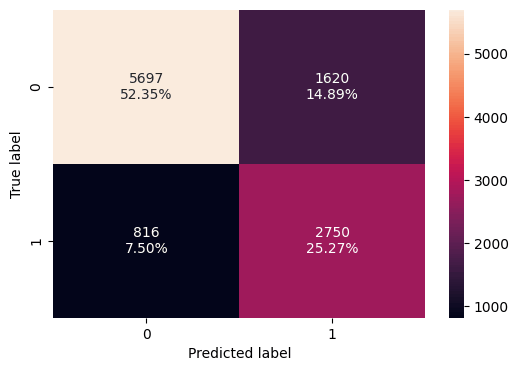

In [103]:
#creating a confusion matrix on test
confusion_matrix_statsmodels(lg2, X_test2, y_test, threshold=optimal_threshold_auc_roc)

In [104]:
#checking model performance for auc-roc on test
log_reg_model_test_perf_threshold_auc_roc = model_performance_classification_statsmodels(lg2, X_test2, y_test, threshold=optimal_threshold_auc_roc)

print('Test performance with optimum threshold')
print(log_reg_model_test_perf_threshold_auc_roc)

Test performance with optimum threshold
   Accuracy  Recall  Precision      F1
0   0.77616 0.77117    0.62929 0.69304


- The model is still performing well having comparable metrics to the training set

####Threshold using Precision-Recall Curve

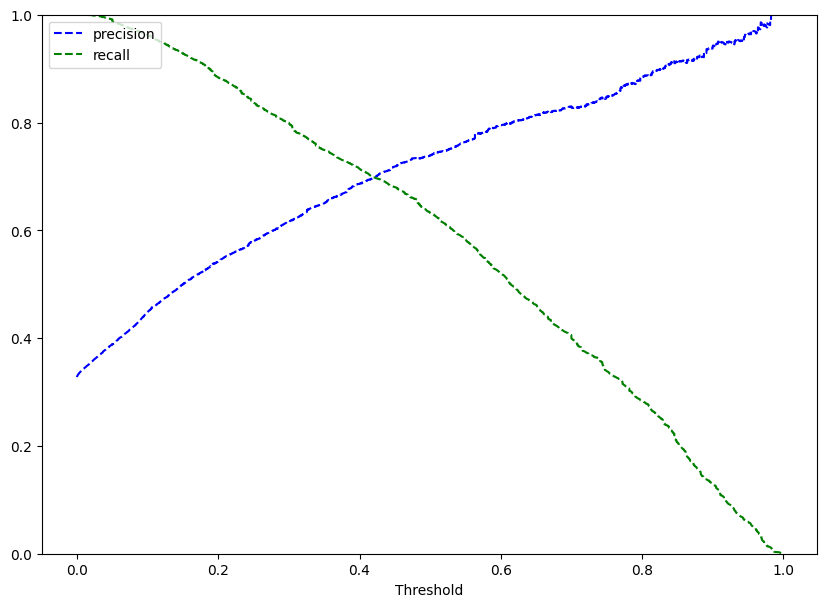

In [105]:
y_scores = lg2.predict(X_train2)
prec, rec, tre = precision_recall_curve(y_train, y_scores)

def plot_prec_recall_vs_thresh(precisions, recalls, thresholds):
  plt.plot(thresholds, precisions[:-1], "b--", label="precision")
  plt.plot(thresholds, recalls[:-1], "g--", label="recall")
  plt.xlabel("Threshold")
  plt.legend(loc="upper left")
  plt.ylim([0, 1])

plt.figure(figsize=(10,7))
plot_prec_recall_vs_thresh (prec, rec, tre)
plt.show()


- At the threshold of 0.43, we get a balanced precision and recall

In [106]:
#setting the threshold
optimal_threshold_curve = .43

checking model performance on trainning set with optimal threshold curve

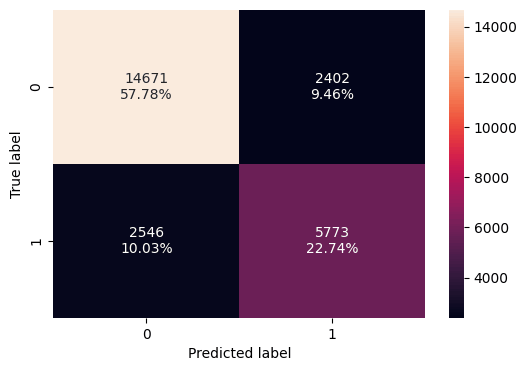

In [107]:
#create a confusion matrix
confusion_matrix_statsmodels(lg2, X_train2, y_train, threshold= optimal_threshold_curve)

In [108]:
log_reg_model_train_perf_threshold_curve = model_performance_classification_statsmodels(lg2, X_train2, y_train, threshold=optimal_threshold_curve)

print('Training Performance')
log_reg_model_train_perf_threshold_curve

Training Performance


,Accuracy,Recall,Precision,F1
0,0.80514,0.69395,0.70618,0.70001


- model is performing well on the training set
- The F1 and Recall scores improved
- The precision score decreased
- Accuracy remained relatively constant

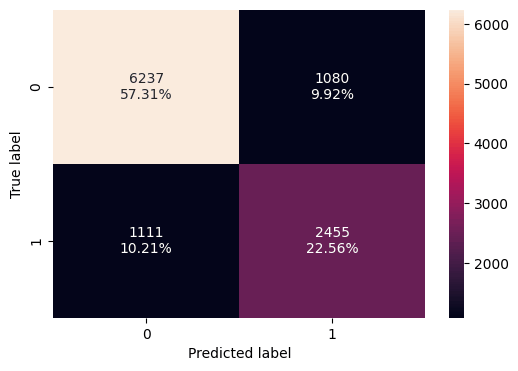

In [109]:
#create a confusion matrix on test
confusion_matrix_statsmodels(lg2, X_test2, y_test, threshold= optimal_threshold_curve)

In [110]:
log_reg_model_test_perf_threshold_curve = model_performance_classification_statsmodels(lg2, X_test2, y_test, threshold=optimal_threshold_curve)

print('Test Performance')
log_reg_model_test_perf_threshold_curve

Test Performance


,Accuracy,Recall,Precision,F1
0,0.79868,0.68845,0.69448,0.69145


- Train and test scores remain comparable

### Model performance evaluation

In [111]:
#training performance comparison

models_train_comp_df = pd.concat(
    [log_reg_model_train_perf.T,
     log_reg_model_train_perf_threshold_auc_roc.T,
     log_reg_model_train_perf_threshold_curve.T
    ],
    axis=1
)
models_train_comp_df.columns= [
    'Logistic Regression-default Threshold (.5)',
    'Logistic Regression-AUC-ROC Threshold (.33)',
    'Logistic Regression-Threshold (.43)'
]

print('Training Performance Comparison')
models_train_comp_df

Training Performance Comparison


,Logistic Regression-default Threshold (.5),Logistic Regression-AUC-ROC Threshold (.33),Logistic Regression-Threshold (.43)
Accuracy,0.80647,0.78186,0.80514
Recall,0.63253,0.77065,0.69395
Precision,0.73915,0.63842,0.70618
F1,0.68169,0.69833,0.70001


In [112]:
#test performance comparison
models_test_comp_df = pd.concat(
    [log_reg_model_test_perf.T,
     log_reg_model_test_perf_threshold_auc_roc.T,
     log_reg_model_test_perf_threshold_curve.T
    ],
    axis=1
)
models_test_comp_df.columns= [
    'Logistic Regression-default Threshold (.5)',
    'Logistic Regression-AUC-ROC Threshold (.33)',
    'Logistic Regression-Threshold (.43)'
]

print('Test Performance Comparison')
models_test_comp_df

Test Performance Comparison


,Logistic Regression-default Threshold (.5),Logistic Regression-AUC-ROC Threshold (.33),Logistic Regression-Threshold (.43)
Accuracy,0.80272,0.77616,0.79868
Recall,0.62675,0.77117,0.68845
Precision,0.73255,0.62929,0.69448
F1,0.67553,0.69304,0.69145


- All three models are performing well on the test and training sets since metrics are comparable between the two sets.
- The models with thresholds .33 and .43 are marginally different in respect to F1 Score which is our target metric, .33 being slightly higher than .43
  - Since we're looking to minimize both recall and precision targeting both false positives and flase negatives, the .43 model will be a better selection.
  - The .33 threshold model has the highest recall performance however the precision performance is the worst in comparison to the other models.

- The Logistic Regression Threshold (.43) can be selected as the final model since Recall and Precision are performing at relatively the same level which is what we are looking to accomplish.


## Model Building - Decision Tree

### Defining Functions for Decision Tree Analysis

In [143]:
#defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
  """
  Function to compute metrics to check classification model performance

  model: classifier
  predictors: independent variables
  target: dependent variables

  """

  #predicting using the independent variables
  pred= model.predict(predictors)

  acc = accuracy_score(target, pred) #compute Accuracy
  recall = recall_score(target, pred) #compute Recall
  precision = precision_score(target, pred) #compute Precision
  f1 = f1_score(target, pred) #compute F1-Score

    #creating a dataframe for the metrics
  df_perf = pd.DataFrame(
      {'Accuracy': acc, 'Recall': recall, 'Precision': precision, 'F1':f1},index=[0]

  )

  return df_perf



In [144]:
def confusion_matrix_sklearn(model, predictors, target):
  """
  To plot the confusion_matrix with percentages
  model: classifier
  predictors: independent variables
  target: dependent variable

  """
  y_pred = model.predict(predictors)
  cm = confusion_matrix(target, y_pred)
  labels = np.asarray(
      [
          ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
          for item in cm.flatten()
          ]
      ).reshape(2, 2)

  plt.figure(figsize=(6, 4))
  sns.heatmap(cm, annot=labels, fmt="")
  plt.ylabel("True label")
  plt.xlabel("Predicted label")

### Data Preparation for Decision Tree Modeling

In [145]:
x=data.drop(['booking_status'], axis=1)
y= data['booking_status']

x=pd.get_dummies(x, drop_first=True)

#splitting data into train and test sets
x_train, x_test, y_train, y_test =train_test_split(
    x, y, test_size=0.30, random_state=1, stratify=y
)

In [146]:
#check to see that the split worked correctly
print('x_train shape', x_train.shape)
print('x_test shape', x_test.shape)
print('y_train shape', y_train.shape )
print('y_test shape', y_test.shape)
print('Percentage of classes in test set:')
print(y_train.value_counts(normalize=True))
print('Percentage of classes in test set:')
print(y_test.value_counts(normalize=True))

x_train shape (25392, 27)
x_test shape (10883, 27)
y_train shape (25392,)
y_test shape (10883,)
Percentage of classes in test set:
0   0.67238
1   0.32762
Name: booking_status, dtype: float64
Percentage of classes in test set:
0   0.67233
1   0.32767
Name: booking_status, dtype: float64


- We see that the proportion of not cancelled (0) 67.2% and cancelled (1) 32.8% is preserved in both training and test sets.

In [147]:
x_train.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,type_of_meal_plan_Meal Plan 2,type_of_meal_plan_Meal Plan 3,type_of_meal_plan_Not Selected,room_type_reserved_Room_Type 2,room_type_reserved_Room_Type 3,room_type_reserved_Room_Type 4,room_type_reserved_Room_Type 5,room_type_reserved_Room_Type 6,room_type_reserved_Room_Type 7,market_segment_type_Complementary,market_segment_type_Corporate,market_segment_type_Offline,market_segment_type_Online
6870,2,0,2,3,0,5,2018,12,30,0,0,0,116.00000,1,0,0,0,0,0,0,0,0,0,0,0,0,1
531,2,1,0,3,0,86,2018,12,8,0,0,0,122.00000,0,0,0,0,0,0,0,0,0,0,0,0,0,1
3394,1,0,0,3,0,105,2018,5,5,0,0,0,117.30000,0,0,0,0,0,0,0,0,0,0,0,0,0,1
23540,1,0,1,1,0,85,2018,12,3,0,0,0,98.00000,0,0,0,0,0,0,0,0,0,0,0,0,0,1
15302,2,0,1,2,0,309,2018,5,13,0,0,0,101.00000,0,1,0,0,0,0,0,0,0,0,0,0,1,0


###Model Building

In [148]:
#create initial tree
model0 = DecisionTreeClassifier(random_state=1)
model0.fit(x_train, y_train)

DecisionTreeClassifier(random_state=1)

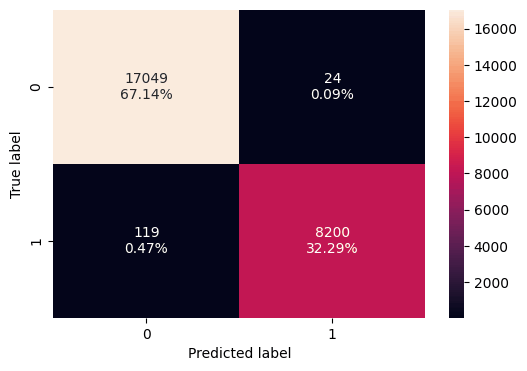

In [149]:
#create confusion matrix on train data
confusion_matrix_sklearn(model0, x_train, y_train)

In [150]:
decision_tree_perf_train_without = model_performance_classification_sklearn(
    model0, x_train, y_train
)
print('Training Performance')
decision_tree_perf_train_without

Training Performance


,Accuracy,Recall,Precision,F1
0,0.99437,0.98570,0.99708,0.99136


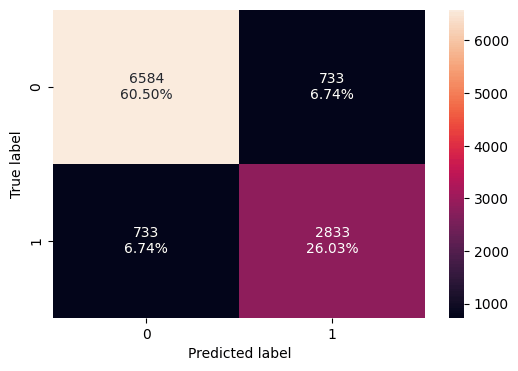

In [151]:
#create confusion matrix on test data
confusion_matrix_sklearn(model0, x_test, y_test)

In [152]:
decision_tree_perf_test_without = model_performance_classification_sklearn(
    model0, x_test, y_test
)
print('Test Performance')
decision_tree_perf_test_without

Test Performance


,Accuracy,Recall,Precision,F1
0,0.86529,0.79445,0.79445,0.79445


###Decision Tree with class_weights

- If the frequency of class 1 (cancelled) is 32.8% and class 0 (not cancelled) is 67.2%, then class 0 will become the dominant class and the decision tree will be biased toward the dominant class

- To account for this we will set class_weight = 'balanced', which will adjust the weights to be inversely proportional to the class frequencies in the input data.

In [153]:
model = DecisionTreeClassifier(random_state=1, class_weight='balanced')
model.fit(x_train, y_train)

DecisionTreeClassifier(class_weight='balanced', random_state=1)

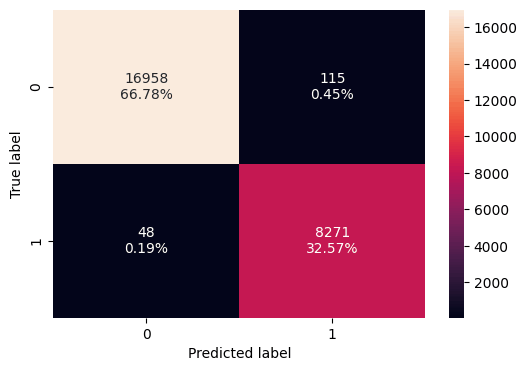

In [154]:
#create confusion matrix on train data
confusion_matrix_sklearn(model, x_train, y_train)

In [155]:
decision_tree_perf_train = model_performance_classification_sklearn(
    model, x_train, y_train
)
print('Training Performance')
decision_tree_perf_train

Training Performance


,Accuracy,Recall,Precision,F1
0,0.99358,0.99423,0.98629,0.99024


- The model is able to almost perfrectly classify all the data points in the training set. All metrics are performing above 98.6%
- The F1 Score is performing at ~0.99 which is nearly perfect
- There are 48 (.19%) False Positives (FP) and 115 (.45%) False Negatives (FN)
- We will compare this to our test performance to see if the tree is overfitting, which it most likely is because no restrictions have been placed on the tree so far.

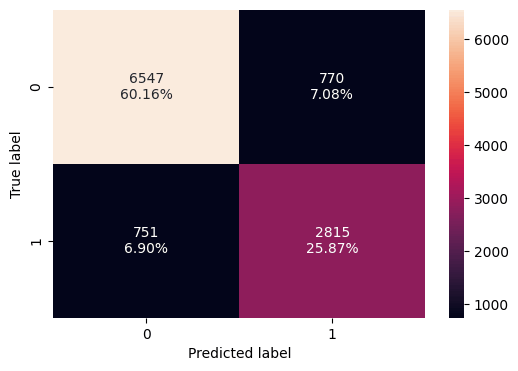

In [156]:
#create confusion matrix on test data
confusion_matrix_sklearn(model, x_test, y_test)

In [157]:
decision_tree_perf_test = model_performance_classification_sklearn(
    model, x_test, y_test
)
print('Test Performance')
decision_tree_perf_test

Test Performance


,Accuracy,Recall,Precision,F1
0,0.86024,0.78940,0.78522,0.78730


- There is a large disparity between the train and test set, which suggests the model is overfitting.



**The next step would be to prune the tree to improve the generalization of the tree by reducing overfitting.**

###Decision Tree Pre-pruning

**Using GridSearch for Hyperparameter tuning of the tree model**

- Since there is no direct way to calculate how a change in hyperparameter values will reduce loos in the tree, we will experiment using GridSearch
- GridSearch is a tuning technique which attempts to compute the optimum values of hyperparemeters reducing loss.
- The parameters of the estimator/model used to apply these methods are optimized by cross-validated grid-search over a parameter grid.

In [158]:
#choose the type of classifier
estimator = DecisionTreeClassifier(random_state=1)

#grid of parameters to choose from
parameters = {
    'class_weight': [None, 'balanced'],
    'max_depth': np.arange(2,7,2),
    'max_leaf_nodes': [50,75,150,250],
    'min_samples_split': [10,30,50,70]
}

#type of scoring used to compare parameter combinations
acc_scorer = make_scorer(f1_score)

#run the grid search
grid_obj = GridSearchCV(estimator, parameters, scoring=acc_scorer, cv=5)
grid_obj = grid_obj.fit(x_train, y_train)

#set the clf to the best combination of parameters
estimator = grid_obj.best_estimator_

#fit the best algorithm to the data
estimator.fit(x_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=6, max_leaf_nodes=50,
                       min_samples_split=70, random_state=1)

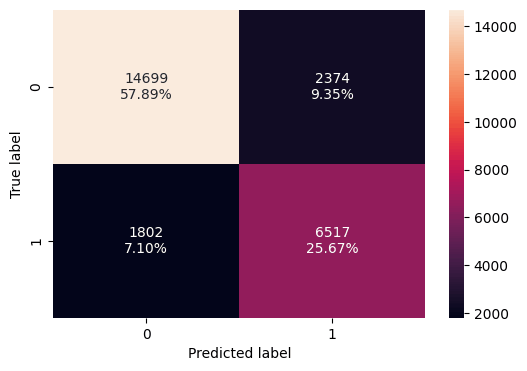

In [159]:
confusion_matrix_sklearn(estimator, x_train, y_train)

In [160]:
decision_tree_tune_perf_train = model_performance_classification_sklearn(
    estimator, x_train, y_train
)
print('Training Performance')
decision_tree_tune_perf_train

Training Performance


,Accuracy,Recall,Precision,F1
0,0.83554,0.78339,0.73299,0.75735


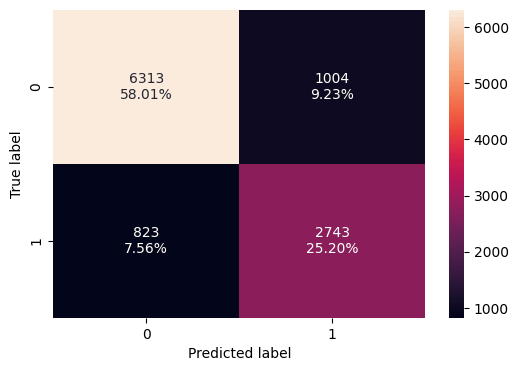

In [161]:
confusion_matrix_sklearn(estimator, x_test, y_test)

In [162]:
decision_tree_tune_perf_test = model_performance_classification_sklearn(
    estimator, x_test, y_test
)
print('Test Performance')
decision_tree_tune_perf_test

Test Performance


,Accuracy,Recall,Precision,F1
0,0.83212,0.76921,0.73205,0.75017


- The model is giving a generalized results since the test and train model metrics are comparable, namely with respect to the F1 Score
  - Train = 0.75735
  - Test = 0.75017

**Feature Importances**

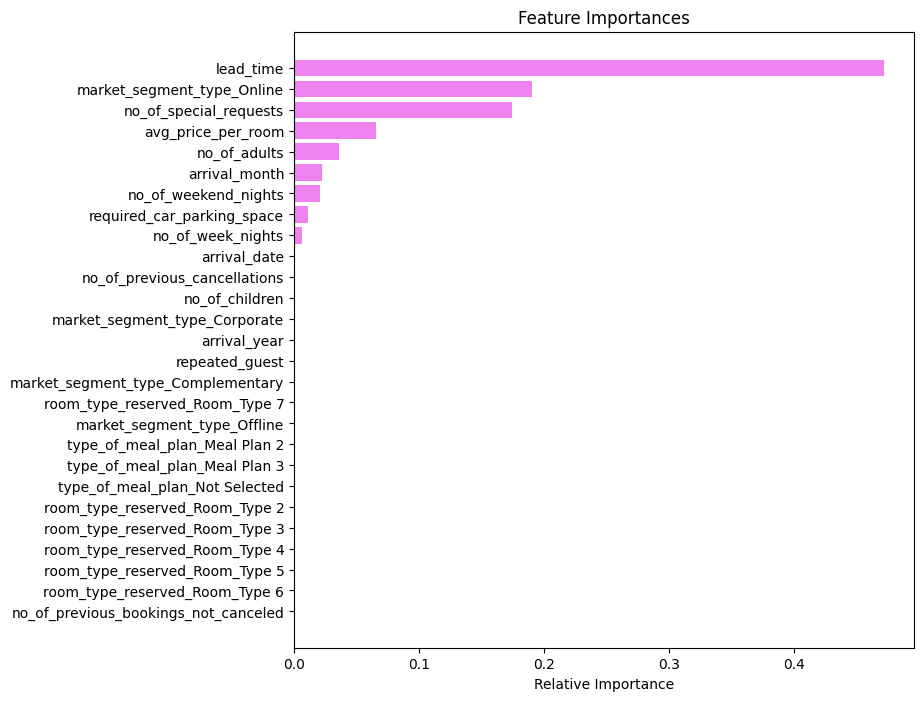

In [163]:
feature_names= list(x_train.columns)
importances = estimator.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

In the pre tuned tree lead_time, market_segment_type_online and no_of_special_requests are the most important features.

###Visualizing Decision Tree

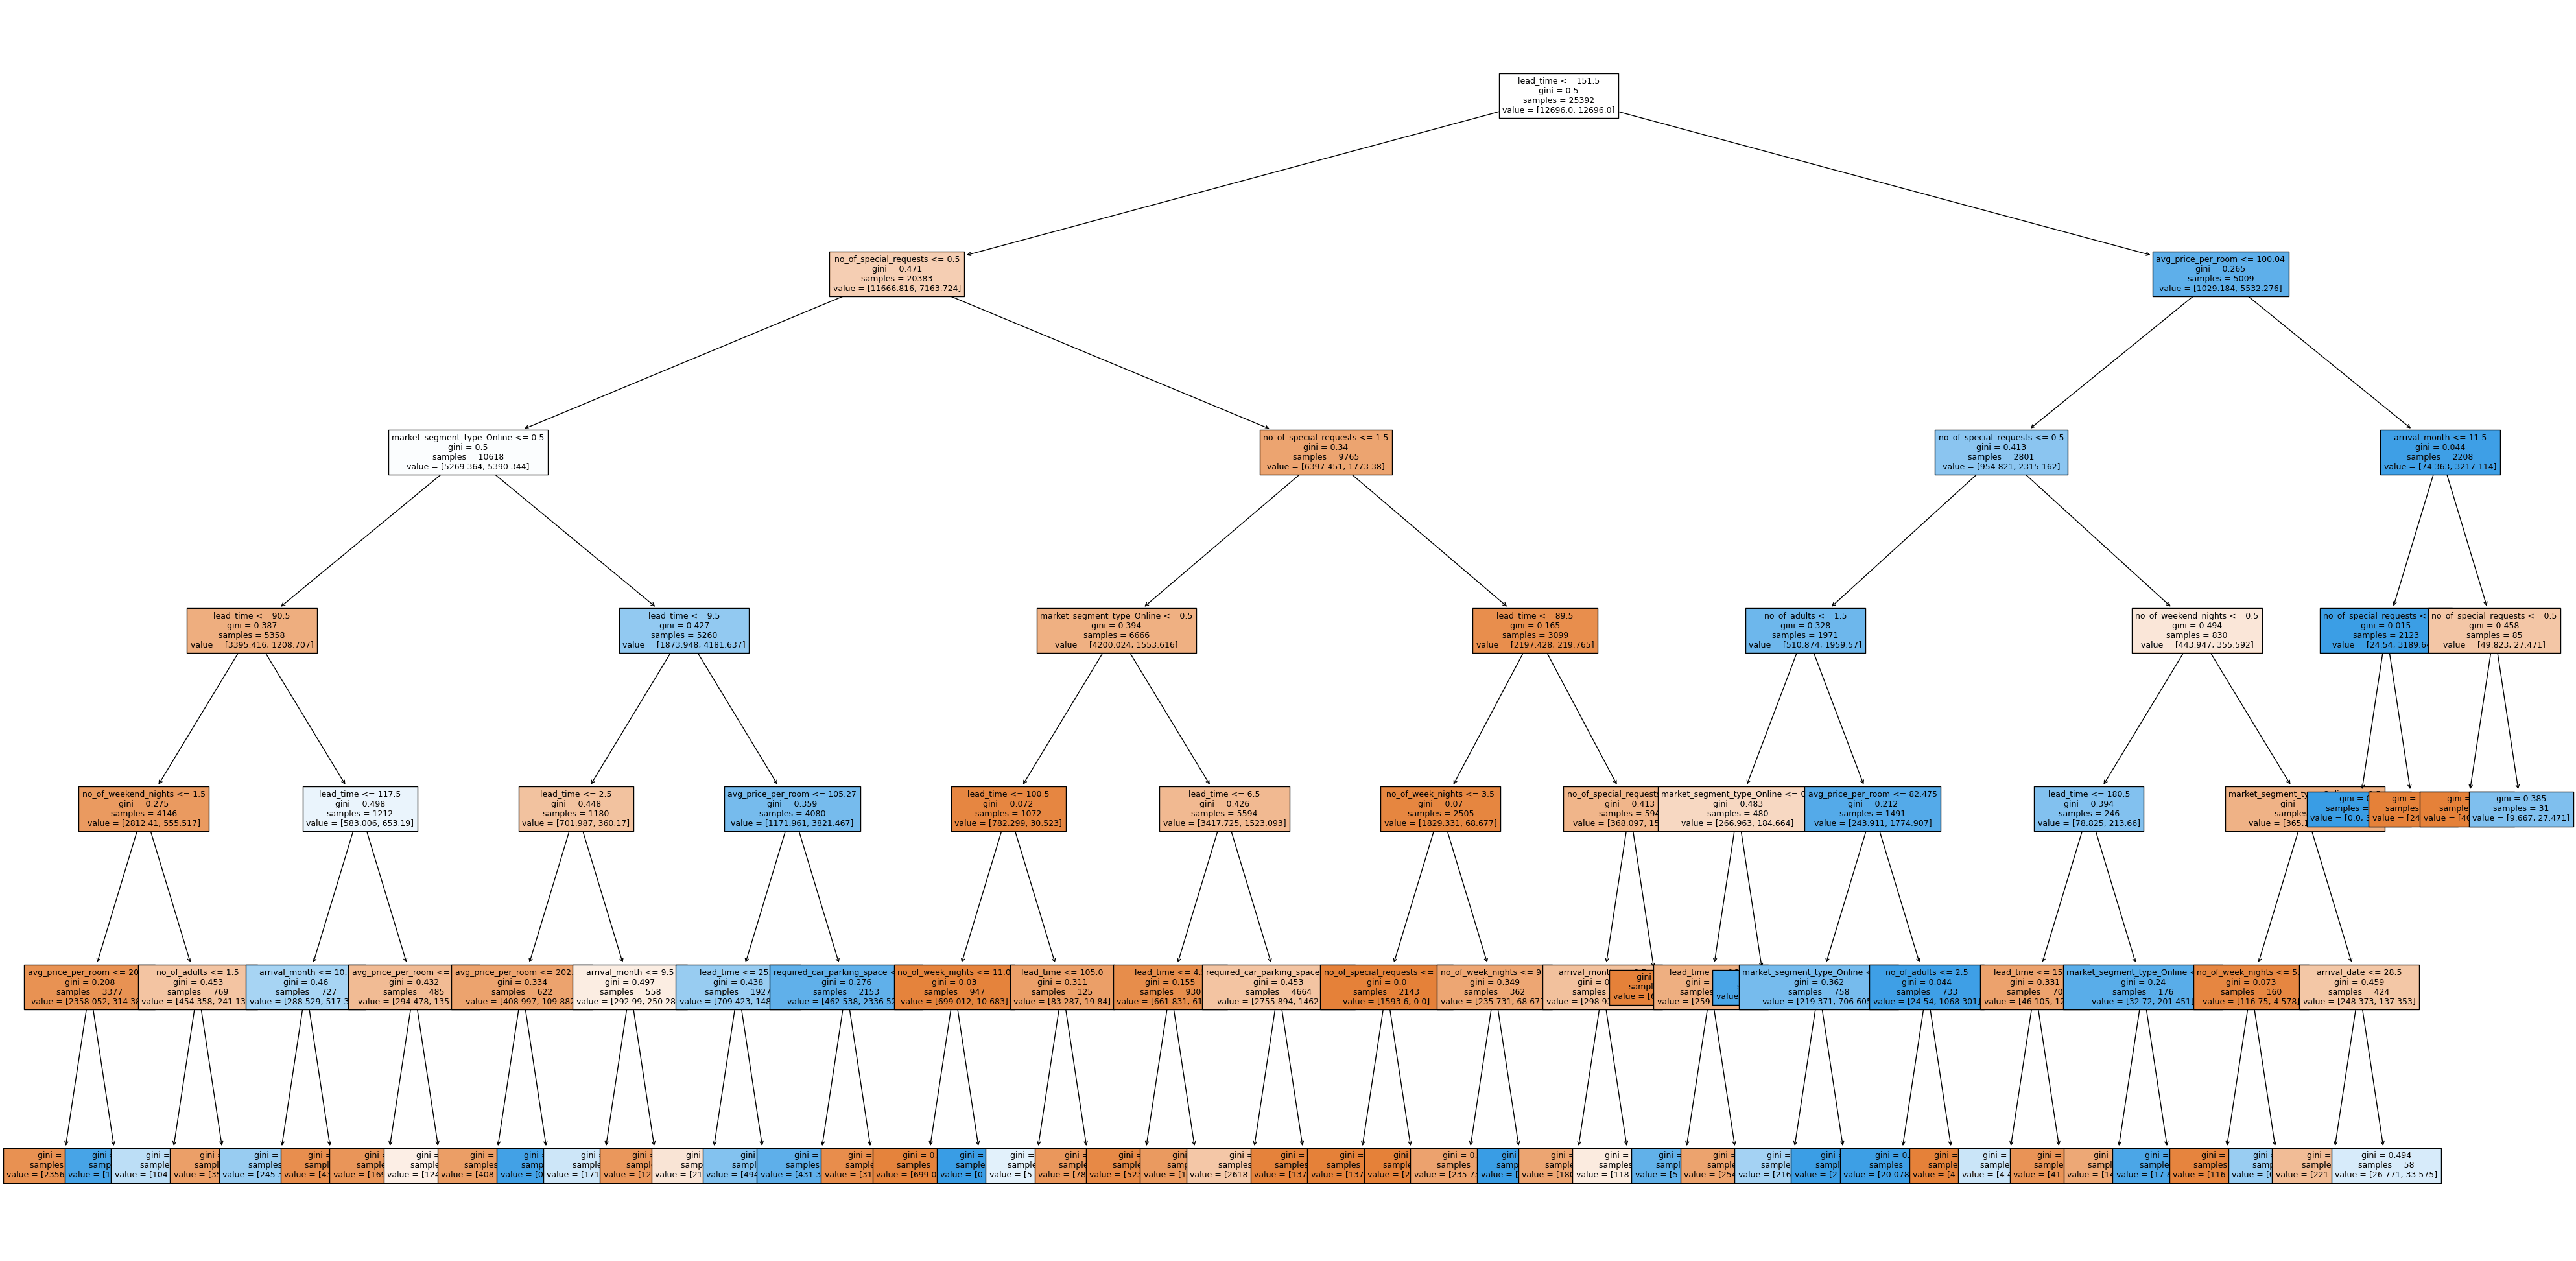

In [164]:
plt.figure(figsize=(50, 25))
out = tree.plot_tree(
    estimator,
    feature_names=feature_names,
    filled=True,
    fontsize=9,
    node_ids=False,
    class_names=None,
)
# below code will add arrows to the decision tree split if they are missing
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor("black")
        arrow.set_linewidth(1)
plt.show()

In [165]:
#Text Breakdown of Decision Tree
print(tree.export_text(estimator, feature_names=feature_names, show_weights=True))

|--- lead_time <= 151.50
|   |--- no_of_special_requests <= 0.50
|   |   |--- market_segment_type_Online <= 0.50
|   |   |   |--- lead_time <= 90.50
|   |   |   |   |--- no_of_weekend_nights <= 1.50
|   |   |   |   |   |--- avg_price_per_room <= 202.00
|   |   |   |   |   |   |--- weights: [2356.56, 293.02] class: 0
|   |   |   |   |   |--- avg_price_per_room >  202.00
|   |   |   |   |   |   |--- weights: [1.49, 21.37] class: 1
|   |   |   |   |--- no_of_weekend_nights >  1.50
|   |   |   |   |   |--- no_of_adults <= 1.50
|   |   |   |   |   |   |--- weights: [104.11, 157.19] class: 1
|   |   |   |   |   |--- no_of_adults >  1.50
|   |   |   |   |   |   |--- weights: [350.25, 83.94] class: 0
|   |   |   |--- lead_time >  90.50
|   |   |   |   |--- lead_time <= 117.50
|   |   |   |   |   |--- arrival_month <= 10.50
|   |   |   |   |   |   |--- weights: [245.40, 512.78] class: 1
|   |   |   |   |   |--- arrival_month >  10.50
|   |   |   |   |   |   |--- weights: [43.13, 4.58] class: 0


Observations from the pre-pruned tree:

Using the above decision rules we can make interpretations from the model like the following:

- If the lead time is less than or equal to 151.50 days, there are no special requests (no_of_special_requests less than or equal to 0.50), the booking was made online (market_segment_type_online greater than 0.50), the lead time is more than 9.50 days, the average price per room is greater than 105.27 Euros and no required car parking space is requested (required_car_parking_space less than or equal to 0.50), then the booking will most likely cancel.

Interpretations from other decision rules can be made similarly.

###Post-pruning

The `DecisionTreeClassifier` provides parameters such as
``min_samples_leaf`` and ``max_depth`` to prevent a tree from overfiting. Cost
complexity pruning provides another option to control the size of a tree. In
`DecisionTreeClassifier`, this pruning technique is parameterized by the
cost complexity parameter, ``ccp_alpha``. Greater values of ``ccp_alpha``
increase the number of nodes pruned. Here we only show the effect of
``ccp_alpha`` on regularizing the trees and how to choose a ``ccp_alpha``
based on validation scores.

**Total impurity of leaves vs effective alphas of pruned tree**

Minimal cost complexity pruning recursively finds the node with the "weakest
link". The weakest link is characterized by an effective alpha, where the
nodes with the smallest effective alpha are pruned first. To get an idea of
what values of ``ccp_alpha`` could be appropriate, scikit-learn provides
`DecisionTreeClassifier.cost_complexity_pruning_path` that returns the
effective alphas and the corresponding total leaf impurities at each step of
the pruning process. As alpha increases, more of the tree is pruned, which
increases the total impurity of its leaves.

In [166]:
clf = DecisionTreeClassifier(random_state=1, class_weight= 'balanced')
path= clf.cost_complexity_pruning_path(x_train, y_train)
ccp_alphas, impurities = abs(path.ccp_alphas), path.impurities


In [167]:
pd.DataFrame(path)

,ccp_alphas,impurities
0,0.00000,0.00833
1,-0.00000,0.00833
2,0.00000,0.00833
3,0.00000,0.00833
4,0.00000,0.00833
...,...,...
1648,0.00938,0.32791
1649,0.00941,0.33732
1650,0.01253,0.34985
1651,0.03405,0.41794


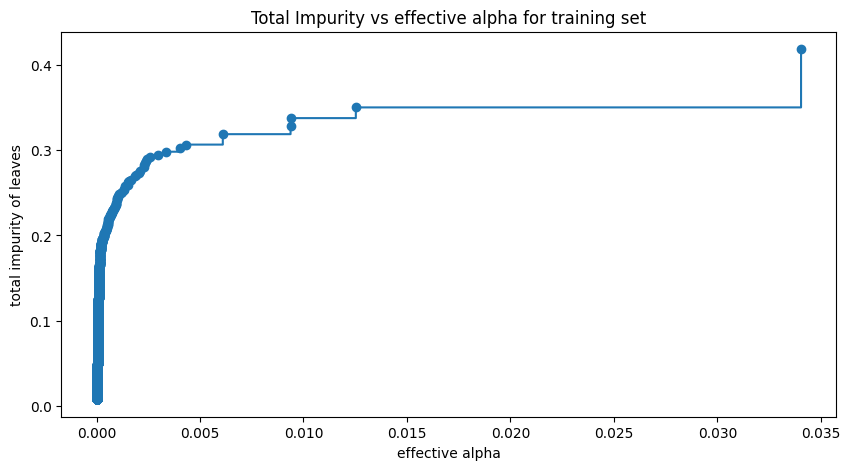

In [168]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set")
plt.show()

Next, we will train a decision tree using the effective alphas. The last value in ccp_alphas is the alpha value that prones the whole tree, leaving the tree with one node (clfs[-1])

In [169]:
clfs = []
for ccp_alpha in ccp_alphas:
  clf=DecisionTreeClassifier(
      random_state=1, ccp_alpha =ccp_alpha, class_weight='balanced'
  )
  clf.fit(x_train, y_train)
  clfs.append(clf)

print('Number of nodes in the last tree is: {} with ccp_alpha: {}'.format(
      clfs[-1].tree_.node_count, ccp_alphas[-1]
      )
)

Number of nodes in the last tree is: 1 with ccp_alpha: 0.08205938055988293


For the remainder, we will remove the last emlement in clfs and ccp_alphas, because it is a trivial tree with only one node. Below we will show how the bumber of nodes and tree depth decreases with an increase in alpha.

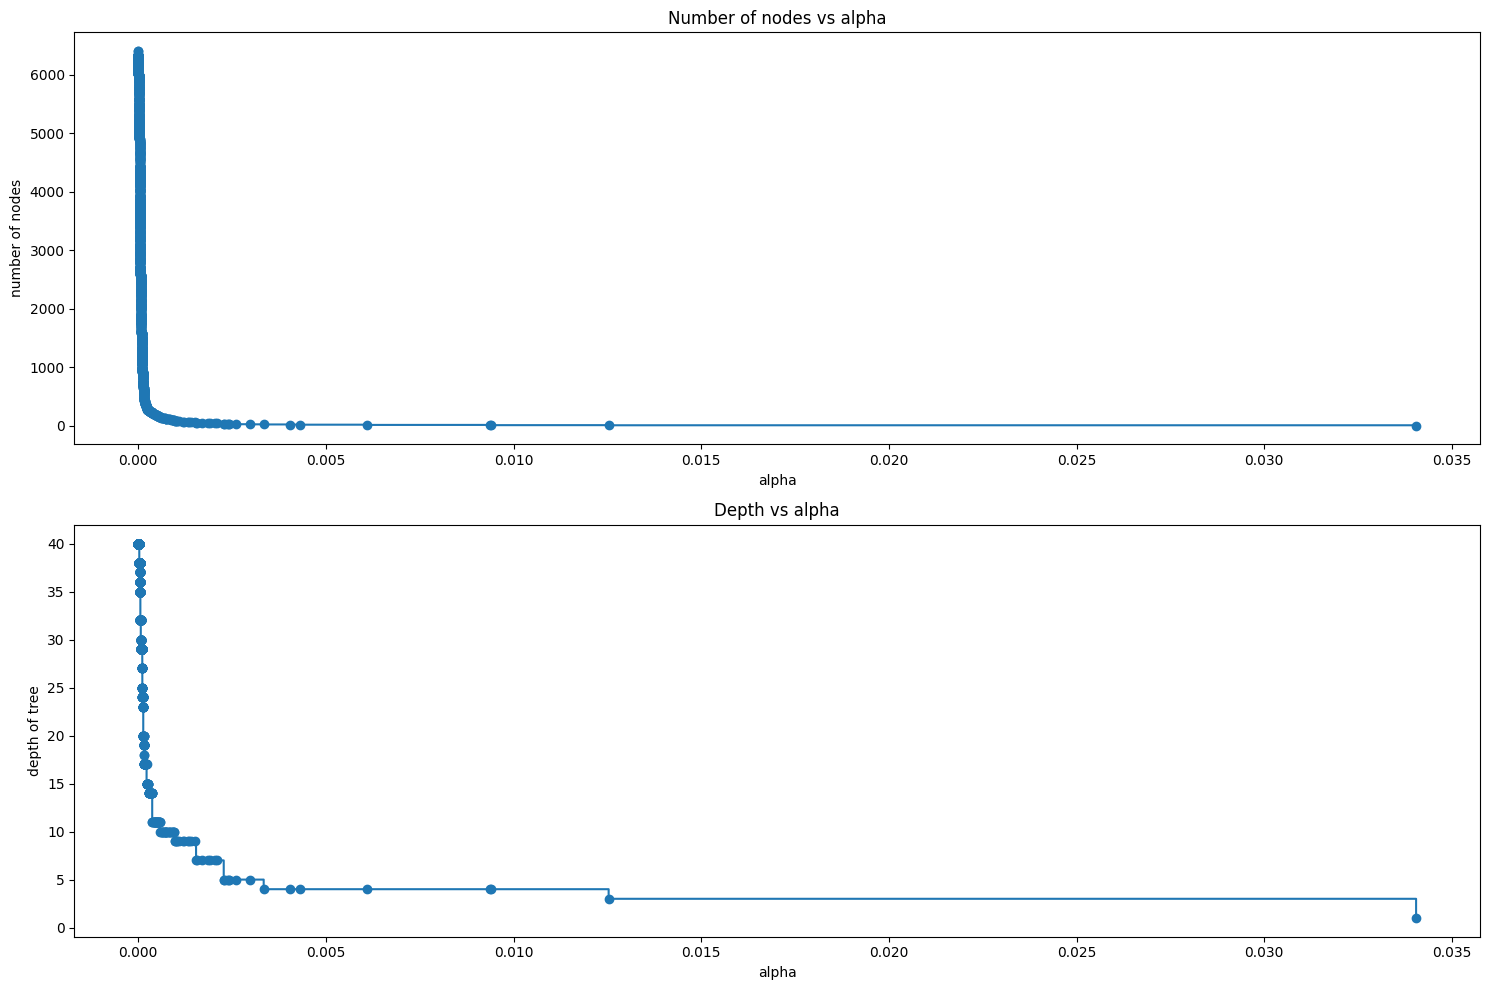

In [170]:
clfs= clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

node_counts= [clf.tree_.node_count for clf in clfs]
depth = [clf.tree_.max_depth for clf in clfs]
fig, ax = plt.subplots(2,1, figsize=(15,10))
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth of tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()

### F1 Score vs Alpha on test and training sets

In [171]:
f1_train =[]
for clf in clfs:
  pred_train = clf.predict(x_train)
  values_train= f1_score(y_train, pred_train)
  f1_train.append(values_train)

f1_test = []
for clf in clfs:
  pred_test = clf.predict(x_test)
  values_test= f1_score(y_test, pred_test)
  f1_test.append(values_test)

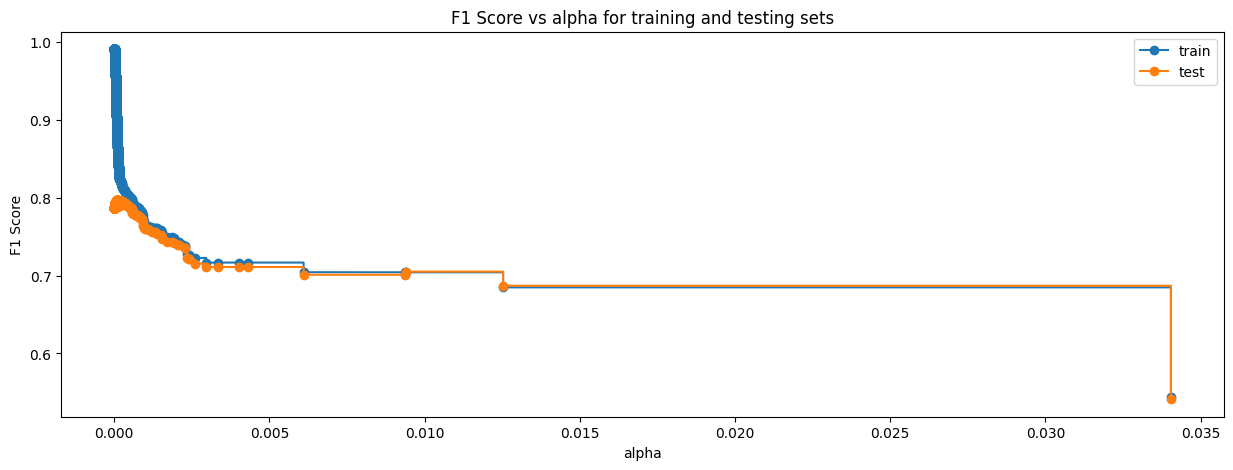

In [172]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.set_xlabel('alpha')
ax.set_ylabel('F1 Score')
ax.set_title('F1 Score vs alpha for training and testing sets')
ax.plot(ccp_alphas, f1_train, marker='o', label='train', drawstyle="steps-post")
ax.plot(ccp_alphas, f1_test, marker="o", label="test", drawstyle="steps-post")
ax.legend()
plt.show()

In [173]:
#creating the model where we get the highest train and test F1 score
index_best_model = np.argmax(f1_test)
best_model = clfs[index_best_model]
print(best_model)

DecisionTreeClassifier(ccp_alpha=0.00010709530427669946,
                       class_weight='balanced', random_state=1)


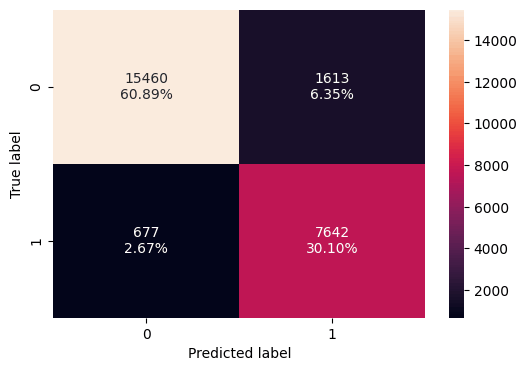

In [174]:
confusion_matrix_sklearn(best_model, x_train, y_train)

In [175]:
decision_tree_post_perf_train = model_performance_classification_sklearn(
    best_model, x_train, y_train
)
print('Training Performance')
decision_tree_post_perf_train

Training Performance


,Accuracy,Recall,Precision,F1
0,0.90981,0.91862,0.82572,0.86969


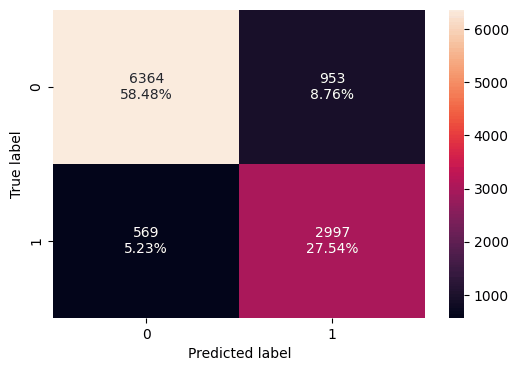

In [176]:
confusion_matrix_sklearn(best_model, x_test, y_test)

In [177]:
decision_tree_post_perf_test = model_performance_classification_sklearn(
    best_model, x_test, y_test
)
print('Test Performance')
decision_tree_post_perf_test

Test Performance


,Accuracy,Recall,Precision,F1
0,0.86015,0.84044,0.75873,0.79750


- In the post pruned tree we see an improvement in F1 Score performance
- However we notice a rather significant difference in the performance of the F1 Score between the training and test sets. This means the model may be suffering from overfitting and is not generalizing well on the test set.
  - If time and resources permit we can further test the performance by splitting the data in to train, holdout and test groups.
  - We would train the model on 60% of the data and apply the model to a holdout and test set both containing 20% of the data respectively.
  - We would then compare the F1 score of the test and the hold out to see if the model performs relatively similarly on the two data sets.

###Visualize Decision Tree

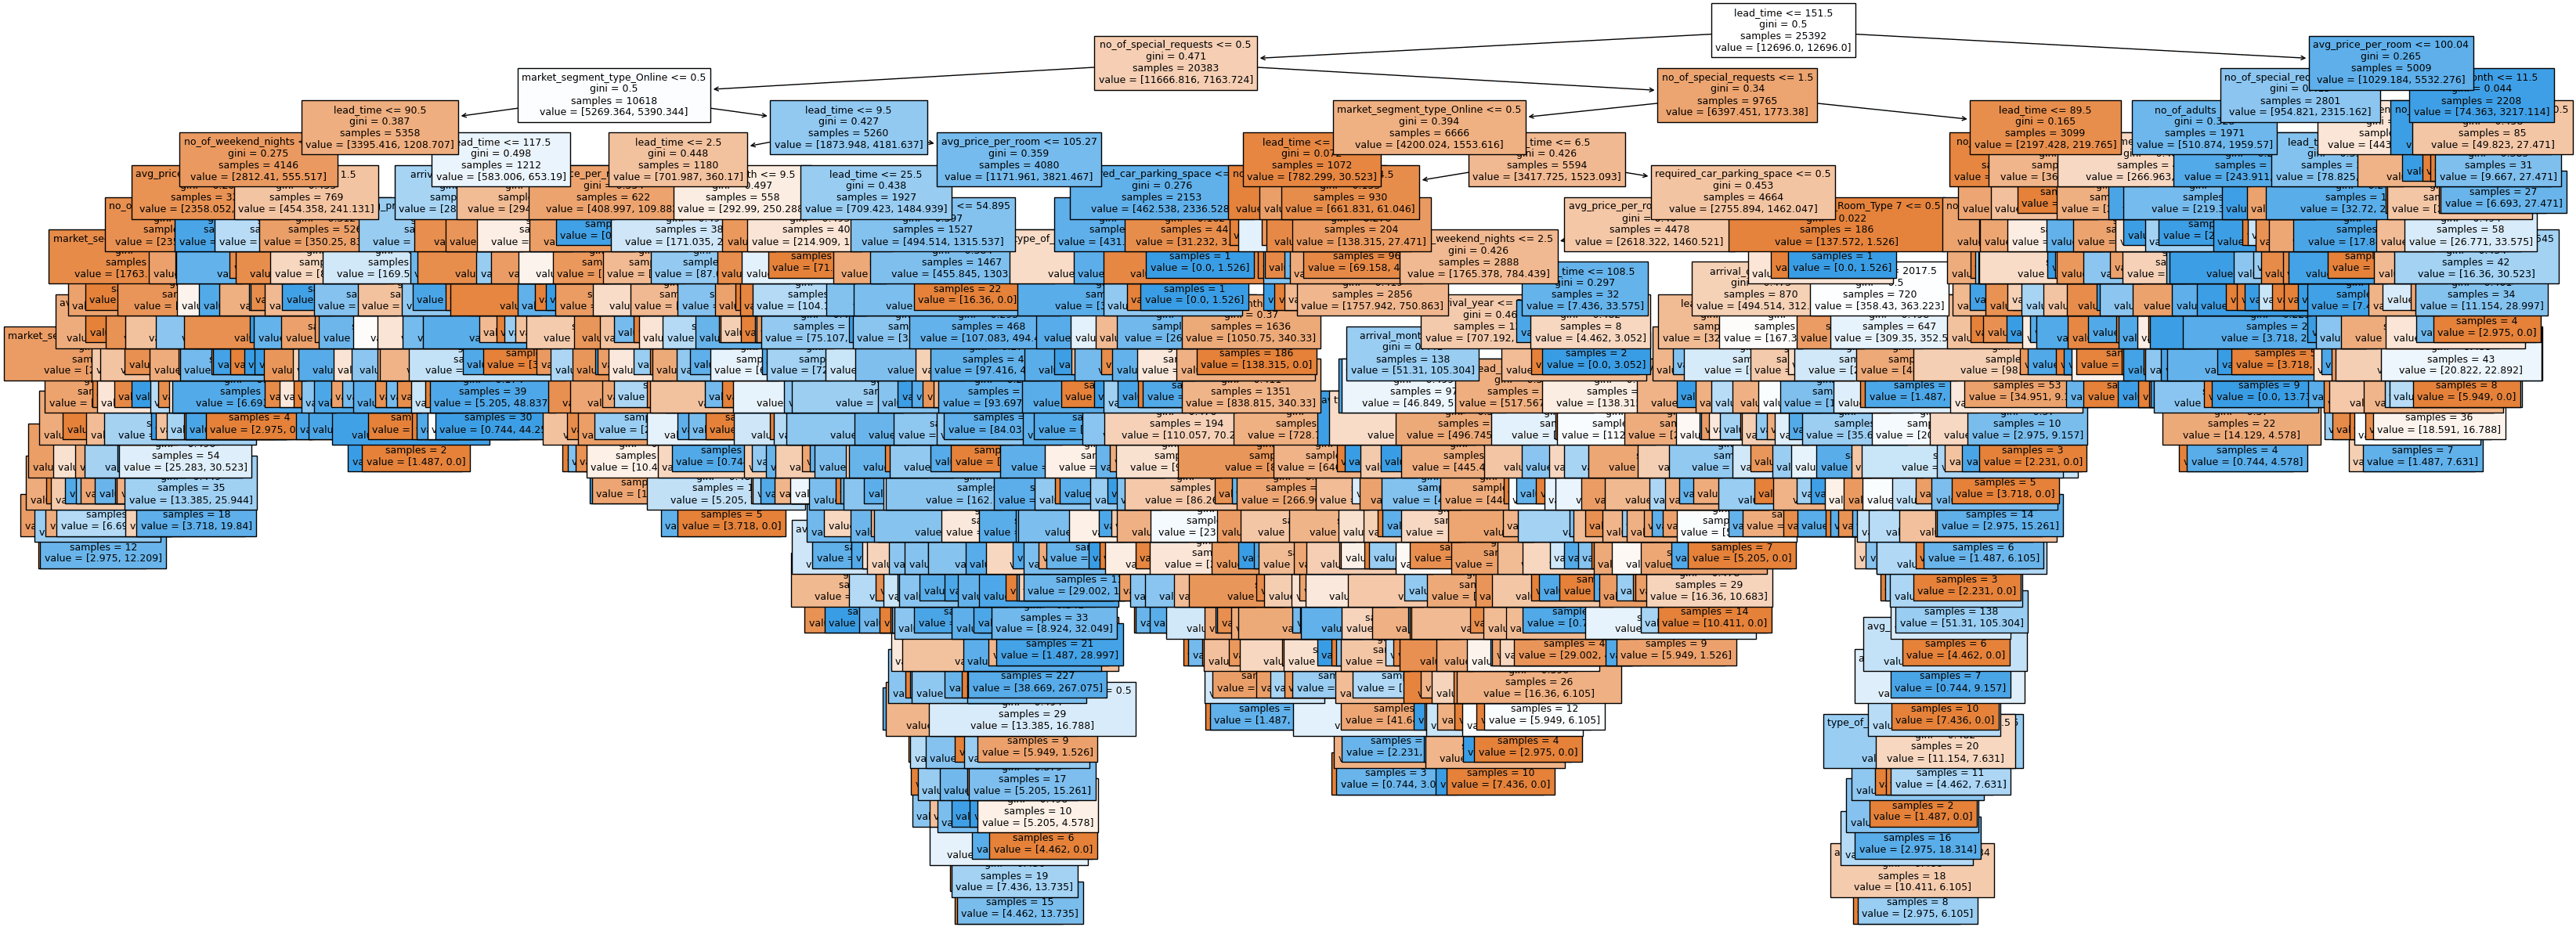

In [178]:
plt.figure(figsize=(40, 15))
out = tree.plot_tree(
    best_model,
    feature_names=feature_names,
    filled=True,
    fontsize=9,
    node_ids=False,
    class_names=None,
)
# below code will add arrows to the decision tree split if they are missing
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor("black")
        arrow.set_linewidth(1)
plt.show()

In [179]:
#Text Breakdown of Decision Tree
print(tree.export_text(best_model, feature_names=feature_names, show_weights=True))

|--- lead_time <= 151.50
|   |--- no_of_special_requests <= 0.50
|   |   |--- market_segment_type_Online <= 0.50
|   |   |   |--- lead_time <= 90.50
|   |   |   |   |--- no_of_weekend_nights <= 1.50
|   |   |   |   |   |--- avg_price_per_room <= 202.00
|   |   |   |   |   |   |--- no_of_weekend_nights <= 0.50
|   |   |   |   |   |   |   |--- market_segment_type_Offline <= 0.50
|   |   |   |   |   |   |   |   |--- repeated_guest <= 0.50
|   |   |   |   |   |   |   |   |   |--- avg_price_per_room <= 87.25
|   |   |   |   |   |   |   |   |   |   |--- market_segment_type_Corporate <= 0.50
|   |   |   |   |   |   |   |   |   |   |   |--- weights: [54.29, 0.00] class: 0
|   |   |   |   |   |   |   |   |   |   |--- market_segment_type_Corporate >  0.50
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |   |   |   |   |   |   |--- avg_price_per_room >  87.25
|   |   |   |   |   |   |   |   |   |   |--- lead_time <= 1.50
|   |   |   |   |   |   |   |   |  

**Interpretations can be made similarly to the tuned decision tree. However, the post-pruned tree is much larger and more complex to compare to the pre-pruned tree. **

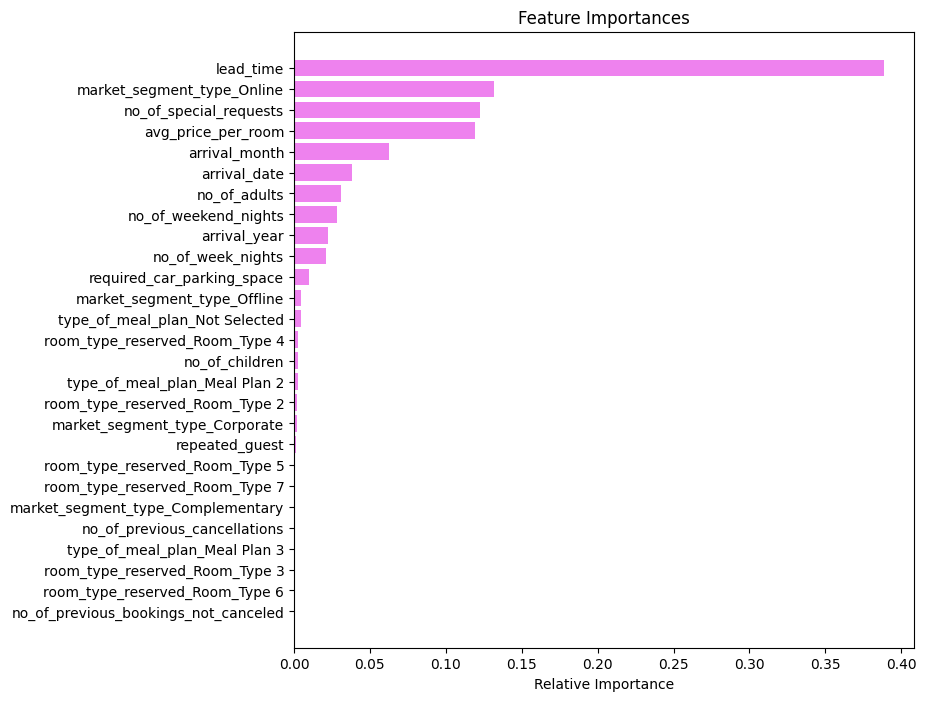

In [180]:
feature_names= list(x_train.columns)
importances = best_model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

- The most important features in the post pruned model are lead_time, market_segment_type_online, no_of_special_requests and avg_price per room.

- The four most important features of both pre and post pruned match which shows the trees logic working in a similar manner.

### Decision Tree Model Performance Comparison and Conclusions

In [181]:
#training performance comparison

models_train_comp_df = pd.concat(
    [decision_tree_perf_train_without.T,
     decision_tree_perf_train.T,
     decision_tree_tune_perf_train.T,
     decision_tree_post_perf_train.T
    ],
    axis=1
)
models_train_comp_df.columns= [
    'Decision Tree - Without class weight',
    'Decision Tree - sklearn',
    'Decision Tree - Pre Pruning',
    'Decision Tree - Post Pruning'
]

print('Training Performance Comparison')
models_train_comp_df

Training Performance Comparison


,Decision Tree - Without class weight,Decision Tree - sklearn,Decision Tree - Pre Pruning,Decision Tree - Post Pruning
Accuracy,0.99437,0.99358,0.83554,0.90981
Recall,0.98570,0.99423,0.78339,0.91862
Precision,0.99708,0.98629,0.73299,0.82572
F1,0.99136,0.99024,0.75735,0.86969


In [182]:
#test performance comparison

models_test_comp_df = pd.concat(
    [decision_tree_perf_test_without.T,
     decision_tree_perf_test.T,
     decision_tree_tune_perf_test.T,
     decision_tree_post_perf_test.T
    ],
    axis=1
)
models_test_comp_df.columns= [
    'Decision Tree - Without class weight',
    'Decision Tree - sklearn',
    'Decision Tree - Pre Pruning',
    'Decision Tree - Post Pruning'
]

print('Test Performance Comparison')
models_test_comp_df

Test Performance Comparison


,Decision Tree - Without class weight,Decision Tree - sklearn,Decision Tree - Pre Pruning,Decision Tree - Post Pruning
Accuracy,0.86529,0.86024,0.83212,0.86015
Recall,0.79445,0.78940,0.76921,0.84044
Precision,0.79445,0.78522,0.73205,0.75873
F1,0.79445,0.78730,0.75017,0.79750


- The post-pruned decision tree is performing the best with respect to F1 compared to all other trees.
- However the Pre-pruned tree is the most generealized model, while the post pruning tree may be capturing too much noise and overfitting due to the difference in performance between the train and test sets.
- Furthermore, the level of complexity in the post-pruned decision tree is much higher compared to that of the pre-pruned tree.

##Final Model Selection and Conclusions

In [183]:
#training performance comparison

final_model_train_comp_df = pd.concat(
    [log_reg_model_train_perf_threshold_curve.T,
     decision_tree_tune_perf_train.T
    ],
    axis=1
)
final_model_train_comp_df.columns= [
    'Logistic Regression-Threshold (.43)',
    'Decision Tree - Pre Pruning'

]

print('Training Performance Comparison')
final_model_train_comp_df

Training Performance Comparison


,Logistic Regression-Threshold (.43),Decision Tree - Pre Pruning
Accuracy,0.80514,0.83554
Recall,0.69395,0.78339
Precision,0.70618,0.73299
F1,0.70001,0.75735


In [184]:
#training performance comparison

final_model_test_comp_df = pd.concat(
    [log_reg_model_test_perf_threshold_curve.T,
     decision_tree_tune_perf_test.T
    ],
    axis=1
)
final_model_test_comp_df.columns= [
    'Logistic Regression-Threshold (.43)',
    'Decision Tree - Pre Pruning'

]

print('Training Performance Comparison')
final_model_test_comp_df

Training Performance Comparison


,Logistic Regression-Threshold (.43),Decision Tree - Pre Pruning
Accuracy,0.79868,0.83212
Recall,0.68845,0.76921
Precision,0.69448,0.73205
F1,0.69145,0.75017


Final Logistic Regression Model

- The Logistic Regression Threshold (.43) can be selected as the final model since Recall and Precision are performing at relatively comparable levels which is what we are looking to accomplish.

- The model is able to predict cancellations with an F1 score of .70 on the training set and .69 on the test set.

- Even though it's F1 score is slightly lower than the threshold .33 model it's precision and recall performance is more balanced, attributing equal importance to reducing the instances of False Positives and False Negatives.

- Coefficients of no_of_weekend_nights, no_of_weeknights, lead_time, arrival_year, no_of_previous_cancellations, avg_price_per_room, some levels of type_of_meal_plan selected and some levels of market_segment_type will are positive and an increase in these leads to an increase in odds of cancelling (reference coefficient interpretations in logistic regression for detail)

- Coefficients of required_car_parking_space, arrival_month, repeated_guest, no_of_special_requests and some levels of room_type_reserved are negative and an increase in these leads to a decrease in odds of cancelling.


**Final Decision Tree Model**
- The pre-pruned decision tree model can be selected since it is able to generalize on both train and tests sets well. It's complexity and depth is much lower than the other trees and will prove to be simpler to implement.

- The model is able to predict cancellations with an F1 score of .76 on the train set and .75 on the test test.

- While the post-prune tree is performing better than the pre-prune; the model may be suffering from over-fitting and a much higher level of complexity.
  - If INN hotels would like, we can explore the post-pruned tree further by applying it to a different data split (60% Train, 20% Holdout, 20% Test) and compare the performance of the model between the holdout and test sets to see if the model is generalizing well or if it in fact is over fitting.

- The most important features in predicting cancellation are lead_time, market_segment_type_Online, no_of_special_requests and avg_price_per_room

- From the decision tree we can predict cancellation if the lead time is less than or equal to 151.50 days, there are no special requests (no_of_special_requests less than or equal to 0.50), the booking was made online (market_segment_type_online greater than 0.50), the lead time is more than 9.50 days, the average price per room is greater than 105.27 Euros and no required car parking space is requested (required_car_parking_space less than or equal to 0.50), then the booking will most likely cancel.
  - We can predict cancellation through other branches by following the same logic in other scenarions (reference pre-pruned decision tree text)

- INN hotels should keep a focus on the important features when reviewing bookings in order to predict cancellations.

**Conclusion**
- INN Hotel could use both the logistic regression model and decision tree model in unison to see if the cancellation prediction on bookings matches. If both predict cancellation or non-cancellation INN hotels can feel secure with the model predictions. However if the predictions are different, the decision tree model having the higher F1 score would be more reliable.
- If one model is preferred the Decision Tree model would be the best model to use for predicting cancellations. It's F1 Score is the best while displaying generalization for prediction.
- If the model isn't performing sufficiently we can re-visit the post-prune tree which is showing a higher performance in respect to F1, however it is likely overfitting. Furthermore, the implementation of the tree would be more complex due to the increased depth and node/leaf count.

## Actionable Insights and Recommendations

- What profitable policies for cancellations and refunds can the hotel adopt?
  - Lead_time is the most important feature contributing to cancellation. The hotel could limit the amount of lead_time allowed for a booking to reduce the lead time of bookings.
    - Another option could be implementing a confirmation schedule on bookings with a long lead time. For example if a booking is made 250 days in advance, confirmations with the guests can be made at 151 days 60 days and 20 days prior to the arrival date.
  - Futhermore, since avg price per room is a contributing factor the hotel can implement a discounted rate for bookings made well in advance of the arrival date reducing the instance of cancellation by counteracting the lead time before arrival by reducing the average price per room.
    - This could be coupled with a reduced non-refundable or partially refundable rate paid at the time of booking to ensure revenue is collected while offering the discounted rate.
  - For stays with a long lead time, a partial comp can be offered to reduce the avg price of the room, especially if they are booked Online. This can also be applied to longer stays where the instance of cancellation is higher. If the lead time and stay length are both long this recommendation would address both features contributing to cancellation.
  - A cancellation fee can be implemented for bookings cancelled within 10 days of the booking.
  - All of these recommendations would be best implemented on bookings made Online as they are one of the highest contributing features towards cancellation.
  

- What other recommedations would you suggest to the hotel?
  - The Hotel should collect data over a longer period of time to expand on the affect of the arrival year. While arrival year coefficient is a positive its increase would lead to an increase in odds of cancellation, this may not hold with the inclusion of future years of data.
  - Experimentation of different policies in the recommendations and collecting data so we can revisit and explore the efficacy of certain policies and which ones should be kept, modified or abandoned.  
